# MinneMUDAC 2026 — Exploratory Data Analysis

**Client:** [The Food Group](https://thefoodgroupmn.org/) (Hunger Solutions is now part of The Food Group)  
**Scope:** Four extracts covering food-shelf activity, partner organizations, SNAP / Market Bucks at farmers markets, and the SNAP benefits helpline.

This notebook profiles every table, flags data-quality issues, and surfaces patterns that matter for later modeling. Figures are generated from the Excel files in this folder.

| File | Grain | Role |
|---|---|---|
| `org_FSStats.xlsx` | Site × month | Monthly food-shelf visits and pounds distributed |
| `Organization.xlsx` | Organization | Partner master file (food banks, shelves, markets, agencies) |
| `marketbucksUsage.xlsx` | Site × market date | SNAP, Market Bucks, and Produce Bucks at farmers markets |
| `Incoming Call.xlsx` | Contact × call | SNAP helpline intake (phone, chat, email, SNAP Rx referrals) |
| `Data_Dictionary.xlsx` | — | Field definitions, deprecated flags, program context |

## 0. Setup

The local `.venv` already has the packages this notebook needs. If you are starting fresh:

```bash
python3 -m venv .venv
source .venv/bin/activate
pip install pandas openpyxl matplotlib seaborn numpy jupyter
```

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

DATA = Path(".")
PALETTE = {
    "ink": "#1F2933",
    "green": "#2F6B4F",
    "gold": "#C47B2B",
    "blue": "#1D4E89",
    "red": "#B42318",
    "gray": "#6B7280",
    "pale": "#E8EEE9",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update(
    {
        "figure.figsize": (10, 4.6),
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.titleweight": "semibold",
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "figure.dpi": 120,
    }
)


def missing_table(df: pd.DataFrame) -> pd.DataFrame:
    n = df.isna().sum()
    out = pd.DataFrame(
        {
            "n_missing": n,
            "pct_missing": (n / len(df) * 100).round(1),
            "n_unique": df.nunique(dropna=True),
            "dtype": df.dtypes.astype(str),
        }
    )
    return out.sort_values("pct_missing", ascending=False)


def barh(series, title, xlabel, color=PALETTE["green"], n=12):
    s = series.dropna().head(n)[::-1]
    fig, ax = plt.subplots(figsize=(9, max(3.2, 0.38 * len(s) + 1.2)))
    ax.barh(s.index.astype(str), s.values, color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    fig.tight_layout()
    plt.show()

In [2]:
calls = pd.read_excel(DATA / "Incoming Call.xlsx")
orgs = pd.read_excel(DATA / "Organization.xlsx")
mb = pd.read_excel(DATA / "marketbucksUsage.xlsx")
fs = pd.read_excel(DATA / "org_FSStats.xlsx")
dictionary = pd.ExcelFile(DATA / "Data_Dictionary.xlsx")

for name, df in [
    ("Incoming Call", calls),
    ("Organization", orgs),
    ("marketbucksUsage", mb),
    ("org_FSStats", fs),
]:
    print(f"{name:20s} {df.shape[0]:>7,} rows × {df.shape[1]:>2} cols")

print("\nDictionary sheets:", dictionary.sheet_names)

Incoming Call         49,727 rows × 31 cols
Organization           1,202 rows × 68 cols
marketbucksUsage      13,573 rows × 19 cols
org_FSStats           28,287 rows × 58 cols

Dictionary sheets: ['Data Catalog', 'org_FSStats | Dictionary', 'Organization | Dictionary', 'MarketBucks | Context', 'MarketBucks | Dictionary', 'Incoming Call | Context', 'Incoming Call | Dictionary']


## Preview — first rows of each extract

Five rows from each table, in the order they appear in the files. Wide tables scroll horizontally in Jupyter.

In [3]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

print("Incoming Call", calls.shape)
display(calls.head())

print("Organization", orgs.shape)
display(orgs.head())

print("marketbucksUsage", mb.shape)
display(mb.head())

print("org_FSStats", fs.shape)
display(fs.head())

Incoming Call (49727, 31)


,__ID,zzCreationTS,zzModificationTS,zzModificationTSNotServer,zzLastArchived,Date,TimeStamp,CallTime,CallLength,CallMethod,Call Answered,Call Description,BestContactMethod,County,Region,NumberInHouse,PrimaryReasonForCall,SNAP Status,BridgeToBenefitsScreen,Application Mailed,SNAPApplicationhelp,isSNAPRx,ReferralInfoEntry,Referral Source,HowHear,FollowUpNeeded,FollowUpNeededDays,Follow up Date,isFollowup1Complete,FollowupDate2,isFollowup2Complete
0,119284,2024-09-11T13:54:54Z,2026-02-13T12:47:16Z,NaN,2025-05-19T15:21:57Z,2024-09-11,2024-09-11T13:54:54Z,13:54:54,NaN,Email,NaN,Sent Text,NaN,( Out of State ),Unknown/Out Of State,4.0,Eligibility Requirements,NaN,NaN,NaN,NaN,NaN,UW-211,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN
1,119285,2024-09-11T13:59:17Z,2026-02-13T12:47:16Z,NaN,2025-09-22T13:41:39Z,2024-09-11,2024-09-11T13:59:17Z,13:59:17,NaN,SNAP Rx,2nd,Sent Text,NaN,Kandiyohi,Southern Minnesota,1.0,SNAP Rx,Screened,NaN,NaN,NaN,1.0,SNAP Info Given\nMNBenefits\nFood Shelf,Southwest State University,NaN,Other,0.0,2024-09-13,1.0,NaT,NaN
2,119286,2024-09-11T14:09:22Z,2026-02-13T12:47:16Z,NaN,2025-09-22T13:41:39Z,2024-09-11,2024-09-11T14:09:22Z,14:09:22,NaN,Voice Mail,NaN,Sent Text,NaN,NaN,NaN,1.0,SUN Bucks,NaN,NaN,NaN,NaN,NaN,SUN Bucks Hotline,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN
3,119287,2024-09-11T14:07:38Z,2026-02-13T12:47:16Z,NaN,2025-09-22T13:41:39Z,2024-09-11,2024-09-11T14:07:38Z,14:07:38,1-5 minutes,Chat Ticket,1st,NaN,NaN,(Unknown),Unknown/Out Of State,1.0,Other,Not Applicable,No,No,NaN,NaN,UW-211,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN
4,119288,2024-09-11T14:09:54Z,2026-02-13T12:47:16Z,NaN,2025-05-19T15:21:57Z,2024-09-11,2024-09-11T14:09:54Z,14:09:54,1-5 minutes,Live Call,NaN,Sent Text,NaN,Hennepin,Twin Cities 7-Metro,1.0,Case-Specific Issues,Currently Enrolled,NaN,NaN,NaN,NaN,County Office,NaN,NaN,NaN,NaN,NaT,NaN,NaT,NaN


Organization (1202, 68)


,__ID,CreateTime,zzCreationTS,zzModificationTS,_id_type,City,State,Zip,MailCity,MailState,MailZip,Eligibility,Conditions,MarketSeasons,zcountDaysOperations,Region,SuperRegion,County,StateDistrict,FederalDistrict,DistrictSection,AgencyType,_id_subtype,AgencySubType,isFoodBank,isAgency,isDistributionSite,HoldsInventoryForOthers,isWebscmShipTo,WebscmShipToName,StateClass,MFS,MCS,cCountSites,isActive,ActiveInactive,InactiveDate,TaxEINVerifiedYN,TaxEINVerifiedDate,TaxEINVerifiedMethod,isTEFAPEligible,isTEFAPEligible_Alert,TefapStatus,TefapActiveDate,TefapInActiveDate,TEFAPElligibilityMeans,SuperShelfStatus,SuperShelfCertDate,_id_Bank,_id_Agency,_id_IfFoodBank,isFindHelpMap,FindHelpMapCategory,_id_findhelpMapCat,z12MoAverage_children,z12MoAverage_Adults,z12MoAverage_Senior,z12MoAverage_Indiv,z12MoAverage_House,z12MoAverage_Pounds,z12MoAverage_LlbsPerPerson,z12MoAverage_PeoplePerHouse,z12MoAverage_TEFAPCases,z12MoAverage_LlbsPerHH,z12MoAverage_Meals,zNameIfActiveBank,block_geoid,is_zip_centroid
0,1.0,System.Byte[],NaN,2026-05-15T19:15:18Z,11.0,Rochester,MN,55904.0,Rochester,MN,55904,NaN,NaN,NaN,7.0,Southern Minnesota,Non-Metro,Olmsted,24.0,1.0,A,Agency or Tribal Nation,NaN,NaN,1.0,1.0,0.0,NaN,1.0,CHANNEL ONE FOOD BANK,0.0,NaN,NaN,2.0,1.0,Active,NaT,NaN,2025-11-01,NaN,1.0,NaN,Active,NaT,NaT,Non-profit tax exempt 501c3,NaN,NaT,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Channel One Regional Food Bank*,2.710900e+14,0.0
1,3.0,System.Byte[],NaN,2026-08-06T10:27:10Z,1.0,Brooklyn Park,MN,55428.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Twin Cities 7-Metro,Metro,Hennepin-Suburbs,NaN,NaN,NaN,Food Bank,NaN,NaN,1.0,NaN,0.0,NaN,1.0,Second Harvest Heartland,0.0,NaN,NaN,NaN,1.0,Active,NaT,NaN,NaT,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaT,3.0,15750.0,3.0,NaN,Food Shelves,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Second Harvest Heartland,2.705303e+14,0.0
2,5.0,System.Byte[],NaN,2026-09-01T02:10:43Z,1.0,East Grand Forks,MN,56721.0,East Grand Forks,MN,56721,NaN,NaN,NaN,NaN,Northern Minnesota,Non-Metro,Polk,1.0,7.0,B,Food Bank,NaN,NaN,1.0,1.0,0.0,NaN,1.0,North Country Food Bank,0.0,NaN,NaN,NaN,1.0,Active,NaT,NaN,NaT,NaN,1.0,NaN,Active,NaT,NaT,Non-profit tax exempt 501c3,NaN,NaT,5.0,5.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,530.0,NaN,NaN,North Country Food Bank Inc.,2.711902e+14,0.0
3,6.0,System.Byte[],NaN,2026-09-03T10:32:32Z,1.0,Duluth,MN,55808.0,Duluth,MN,55808,NaN,NaN,NaN,NaN,Northern Minnesota,Non-Metro,Saint Louis,8.0,8.0,B,Food Bank,NaN,NaN,1.0,NaN,0.0,NaN,1.0,Second Harvest Northland,0.0,NaN,NaN,NaN,1.0,Active,NaT,NaN,NaT,NaN,1.0,NaN,Active,NaT,NaT,NaN,NaN,NaT,6.0,NaN,6.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,108.0,NaN,NaN,Second Harvest Northland,2.713700e+14,0.0
4,7.0,System.Byte[],NaN,2026-01-07T13:35:05Z,1.0,Fargo,ND,58102.0,Fargo,ND,58102,NaN,NaN,NaN,NaN,Central Minnesota,Non-Metro,Clay,NaN,NaN,NaN,Food Bank,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,Inactive,2026-01-07,NaN,NaT,NaN,1.0,NaN,Active,NaT,NaT,NaN,NaN,NaT,7.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.801700e+14,0.0


marketbucksUsage (13573, 19)


,_ID,zzCreationTS,zzCreationDate,zzModificationTS,_id_site,Dated,SNAPDistributed,SNAPRedeemed,MBDistributed,MBRedeemed,GiftCerts,RCGiftCertificates,PBDistributed,PBRedeemed,RCMBDistributed,RCMBRedeemed,Customers,Transactions,isLateEntry
0,7621,2022-01-06T12:46:33Z,2022-01-06,2025-12-30T13:52:32Z,14214,2022-01-04,0.00,0.00,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
1,7622,2022-01-06T12:48:30Z,2022-01-06,2025-12-30T13:52:32Z,14214,2022-01-04,52.61,52.61,8.0,8.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN
2,7623,2022-01-06T12:49:57Z,2022-01-06,2025-12-30T13:52:32Z,14214,2022-01-05,337.72,337.72,85.0,85.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN
3,7624,2022-01-13T10:01:03Z,2022-01-13,2025-12-30T13:52:32Z,14214,2022-01-12,26.74,26.74,7.0,7.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN
4,7628,2022-01-14T09:42:31Z,2022-01-14,2025-12-30T13:52:32Z,14214,2022-01-13,59.09,59.09,50.0,50.0,NaN,NaN,NaN,NaN,NaN,NaN,6.0,NaN,NaN


org_FSStats (28287, 58)


,__ID,_id_site,_Year,_Month,DateForSearch,zzCreationTS,zzModificationTS,AdultsReg,ChildrenReg,HouseholdsReg,IndividualsReg,Meals,Misc,People,PoundsReg,SeniorsReg,Snacks,UniqueVisitsReg,County,FederalDistrict,StateDistrict,FoodBank,ChildrenExtra,ChildrenProduce,ChildrenHoliday,AdultsExtra,AdultsProduce,AdultsHoliday,IndividualsExtra,SeniorsExtra,SeniorsProduce,SeniorsHoliday,IndividualsProduce,IndividualsHoliday,UniqueVisitsExtra,UniqueVisitsProduce,UniqueVisitsHoliday,UniqueVisitsTotal,SeniorsTotal,IndividualsTotal,ChildrenTotal,AdultsTotal,HouseholdsExtra,HouseholdsProduce,HouseholdsHoliday,HouseholdsTotal,PoundsExtra,PoundsProduce,PoundsHoliday,PoundsTotal,AgencyType,_id_bank,SuperShelf,_YearMonth,PoundsPerIndiv,IndividualsPerHH,id_agency,PoundsPerHH
0,2753,1254.0,2022,1,2022-01-01,2022-01-10T21:48:14Z,2025-12-30T13:50:18Z,1519.0,1048.0,1027.0,2706.0,NaN,NaN,NaN,41548.0,139.0,NaN,NaN,St. Louis,8.0,7.0,Second Harvest Northland,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.0,2706.0,1048.0,1519.0,NaN,NaN,NaN,1027.0,NaN,NaN,NaN,41548.0,Brick and Mortar Site,6.0,NaN,202201,15.0,3.0,NaN,40.0
1,2762,14434.0,2022,1,2022-01-01,2022-01-10T15:01:29Z,2025-12-30T13:50:18Z,23.0,16.0,17.0,47.0,NaN,NaN,NaN,900.0,8.0,NaN,NaN,Olmsted,1.0,24.0,Channel One Regional Food Bank,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.0,47.0,16.0,23.0,NaN,NaN,NaN,17.0,NaN,NaN,NaN,900.0,Brick and Mortar Site,1.0,NaN,202201,19.0,3.0,14434.0,53.0
2,12862,1069.0,2022,3,2022-03-01,2022-03-02T16:18:49Z,2026-09-02T20:20:24Z,281.0,27.0,220.0,343.0,NaN,NaN,NaN,21345.0,35.0,NaN,NaN,Hennepin-Minneapolis,5.0,62.0,The Food Group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.0,343.0,27.0,281.0,NaN,NaN,NaN,220.0,NaN,NaN,NaN,21345.0,Food Shelf,14179.0,NaN,202203,62.0,2.0,16988.0,97.0
3,12863,1069.0,2022,1,2022-01-01,2022-03-08T09:50:31Z,2026-09-02T20:20:24Z,281.0,21.0,216.0,330.0,NaN,NaN,NaN,15684.0,28.0,NaN,NaN,Hennepin-Minneapolis,5.0,62.0,The Food Group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,28.0,330.0,21.0,281.0,NaN,NaN,NaN,216.0,NaN,NaN,NaN,15684.0,Food Shelf,14179.0,NaN,202201,48.0,2.0,16988.0,73.0
4,12864,14680.1,2022,1,2022-01-01,2022-03-08T09:50:31Z,2025-12-30T13:50:24Z,142.0,93.0,91.0,266.0,NaN,NaN,NaN,5761.0,31.0,NaN,NaN,Koochiching,8.0,3.0,The Food Group,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31.0,266.0,93.0,142.0,NaN,NaN,NaN,91.0,NaN,NaN,NaN,5761.0,Tribal Program,14179.0,NaN,202201,22.0,3.0,NaN,63.0


## 1. Data catalog and dictionary notes

The dictionary marks several field families as **Deprecated**, **Empty**, or FileMaker audit fields (`FMP`). Those flags match what is in the extracts:

- **org_FSStats:** 24 columns are 100% null (Extra / Produce / Holiday splits, `Misc`, `People`, `Snacks`). `*Total` columns are copies of `*Reg`. `UniqueVisits*` is effectively unused. `PoundsPerIndiv`, `IndividualsPerHH`, and `PoundsPerHH` exist but the dictionary recommends calculating them yourself.
- **Organization:** several flags (`isFoodBank`, `MFS`, `MCS`, `WebscmShipTo*`) are empty. `StateDistrict` / `FederalDistrict` are static and should not be trended across redistricting.
- **Incoming Call:** `SNAPApplicationhelp` is empty. `zz*` columns are audit timestamps.
- **Market Bucks:** SNAPDistributed is tokens loaded; SNAPRedeemed is spent with vendors. Market Bucks match SNAP dollar-for-dollar up to **$10 per visit**. Produce Bucks (PB) and Ramsey County (RC) fields are extra incentive layers.

Join keys: `org_FSStats._id_site` and `marketbucksUsage._id_site` → `Organization.__ID`. Thirteen organizations use **fractional IDs** (e.g. `14680.1`) for satellite sites — do not cast IDs to integers.

In [4]:
catalog = pd.DataFrame(
    [
        {
            "table": "Incoming Call",
            "rows": len(calls),
            "cols": calls.shape[1],
            "grain": "Contact × call",
            "start": pd.to_datetime(calls["Date"]).min().date(),
            "end": pd.to_datetime(calls["Date"]).max().date(),
            "primary_key": "__ID",
            "pk_unique": calls["__ID"].is_unique,
        },
        {
            "table": "Organization",
            "rows": len(orgs),
            "cols": orgs.shape[1],
            "grain": "Organization",
            "start": None,
            "end": None,
            "primary_key": "__ID",
            "pk_unique": orgs["__ID"].is_unique,
        },
        {
            "table": "marketbucksUsage",
            "rows": len(mb),
            "cols": mb.shape[1],
            "grain": "Site × market date",
            "start": pd.to_datetime(mb["Dated"]).min().date(),
            "end": pd.to_datetime(mb["Dated"]).max().date(),
            "primary_key": "_ID",
            "pk_unique": mb["_ID"].is_unique,
        },
        {
            "table": "org_FSStats",
            "rows": len(fs),
            "cols": fs.shape[1],
            "grain": "Site × month",
            "start": pd.to_datetime(fs["DateForSearch"]).min().date(),
            "end": pd.to_datetime(fs["DateForSearch"]).max().date(),
            "primary_key": "__ID",
            "pk_unique": fs["__ID"].is_unique,
        },
    ]
)
catalog

,table,rows,cols,grain,start,end,primary_key,pk_unique
0,Incoming Call,49727,31,Contact × call,2022-02-23,2026-07-31,__ID,False
1,Organization,1202,68,Organization,None,None,__ID,True
2,marketbucksUsage,13573,19,Site × market date,2022-01-01,2026-07-31,_ID,True
3,org_FSStats,28287,58,Site × month,2022-01-01,2026-07-01,__ID,True


In [5]:
usage_rows = []
for sheet in dictionary.sheet_names:
    if "Dictionary" not in sheet:
        continue
    d = pd.read_excel(dictionary, sheet_name=sheet)
    flagged = d[d["Usage"].notna()][["Field Name", "Usage"]]
    flagged.insert(0, "table", sheet.split("|")[0].strip())
    usage_rows.append(flagged)
usage = pd.concat(usage_rows, ignore_index=True)
print("Non-null Usage flags")
usage.groupby(["table", "Usage"]).size().unstack(fill_value=0)

Non-null Usage flags


Usage,Deprecated,Empty,FMP
table,,,
Incoming Call,0,1,4
MarketBucks,0,0,3
Organization,0,8,3
org_FSStats,33,1,2


## 2. Organization master file

1,202 partner records: food banks, brick-and-mortar shelves, farmers markets, meal and outreach programs. Most are **Active** (1,073) and in **Minnesota**. `State` has a few dirty values (zip codes stored in the state column, a trailing newline on `MN`).

In [6]:
print("Active / inactive")
display(orgs["ActiveInactive"].value_counts(dropna=False).to_frame("n"))
print("\nAgency type")
display(orgs["AgencyType"].value_counts(dropna=False).to_frame("n"))
print("\nRegion")
display(orgs["Region"].value_counts(dropna=False).to_frame("n"))
print("\nTEFAP status")
display(orgs["TefapStatus"].value_counts(dropna=False).to_frame("n"))
print("\nFind Help map category")
display(orgs["FindHelpMapCategory"].value_counts(dropna=False).to_frame("n"))
print("\nState (data-quality check)")
display(orgs["State"].value_counts(dropna=False).to_frame("n"))
print("Counties:", orgs["County"].nunique(dropna=True), "| Cities:", orgs["City"].nunique(dropna=True))
print("Fractional site IDs (.1 satellites):", int((orgs["__ID"] != orgs["__ID"].round()).sum()))

Active / inactive


,n
ActiveInactive,
Active,1073
Inactive,121
NaN,8



Agency type


,n
AgencyType,
Brick and Mortar Site,448
Agency or Tribal Nation,317
Farmers Market,185
Outreach Program,93
Meal Program,71
Other,38
NaN,33
College Campus Program,6
Tribal Program,6



Region


...


Find Help map category


,n
FindHelpMapCategory,
NaN,688
Food Shelves,404
Benefits Eligible Farmers Markets,60
Discount Grocery,41
Senior Meals,5
Hot Meals,4



State (data-quality check)


,n
State,
MN,1057
NaN,140
ND,1
MN\n,1
55313,1
55056,1
55318,1


Counties: 92 | Cities: 341
Fractional site IDs (.1 satellites): 13


findfont: Failed to find font weight semibold for Arial, now using 700.


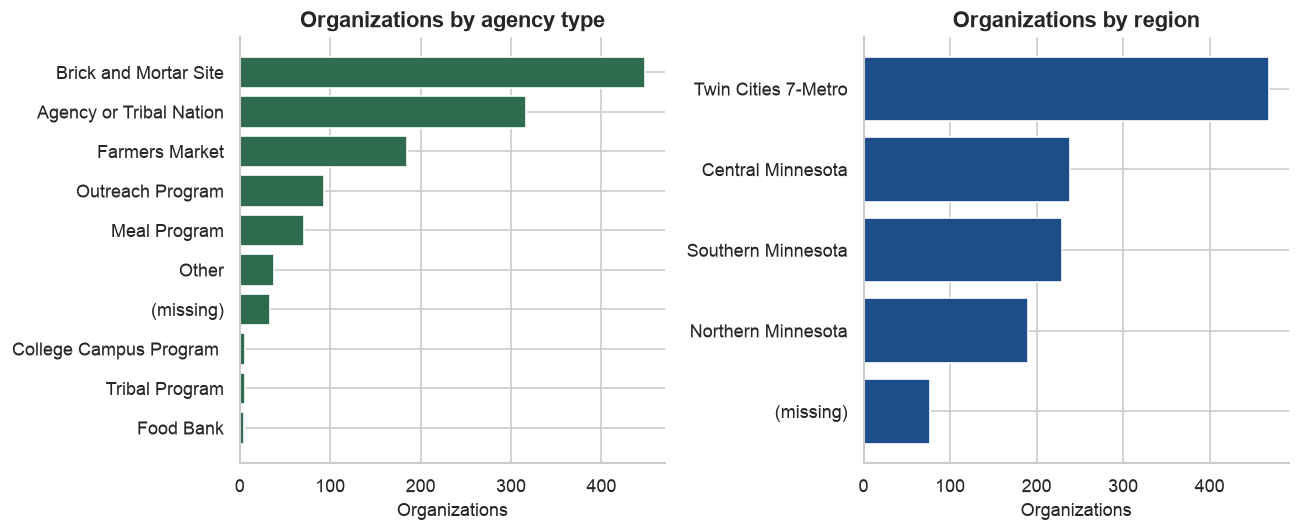

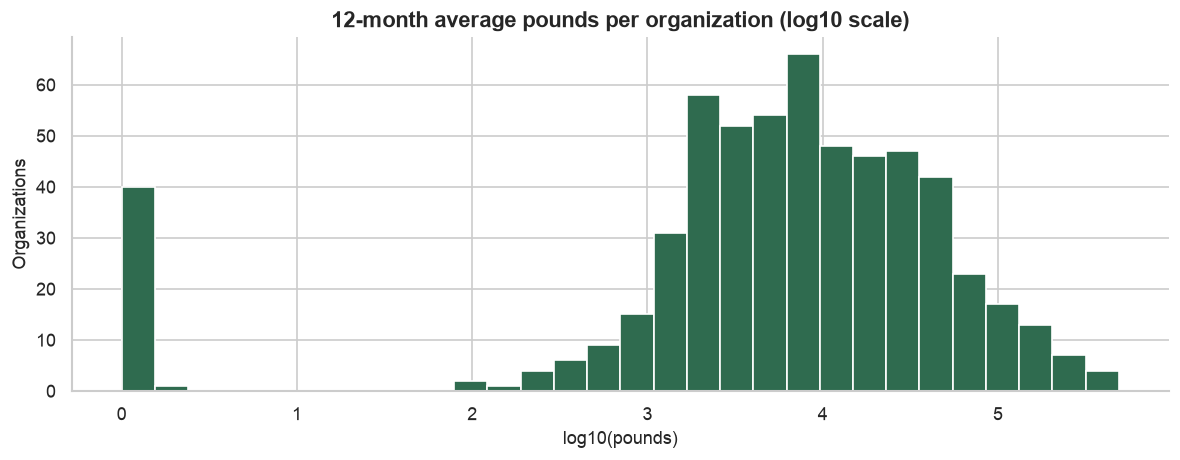

       z12MoAverage_Pounds
count                586.0
mean               25082.7
std                51089.2
min                    0.0
25%                 2266.5
50%                 6889.0
75%                24362.8
max               490057.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))

atype = orgs["AgencyType"].fillna("(missing)").value_counts()
axes[0].barh(atype.index[::-1], atype.values[::-1], color=PALETTE["green"])
axes[0].set_title("Organizations by agency type")
axes[0].set_xlabel("Organizations")

region = orgs["Region"].fillna("(missing)").value_counts()
axes[1].barh(region.index[::-1], region.values[::-1], color=PALETTE["blue"])
axes[1].set_title("Organizations by region")
axes[1].set_xlabel("Organizations")
fig.tight_layout()
plt.show()

pounds12 = orgs["z12MoAverage_Pounds"].dropna()
fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(np.log10(pounds12.clip(lower=1)), bins=30, color=PALETTE["green"], edgecolor="white")
ax.set_title("12-month average pounds per organization (log10 scale)")
ax.set_xlabel("log10(pounds)")
ax.set_ylabel("Organizations")
fig.tight_layout()
plt.show()
print(pounds12.describe().round(1).to_frame("z12MoAverage_Pounds"))

**Takeaways**

- Brick-and-mortar sites (448) and “Agency or Tribal Nation” (317) dominate the roster; 185 farmers markets sit alongside them.
- Coverage is statewide: Non-Metro 657 vs Metro 468, but **volume later in FSStats concentrates in the Twin Cities**.
- Only 586 organizations have a 12-month pound average — that field is a convenience rollup, not a complete census.
- 717 partners are TEFAP-active. 646 appear on the Find Help map (mostly Food Shelves).

## 3. Food-shelf monthly statistics (`org_FSStats`)

28,287 site-months, **665 sites**, January 2022 – July 2026. Usable measures are the `*Reg` fields: adults, children, seniors, households, individuals, and pounds. The Extra/Produce/Holiday family is empty and marked deprecated.

**Important:** `IndividualsReg` / `HouseholdsReg` are **monthly headcounts**, not unique people. Summing them across months counts repeat visitors again. Pounds *can* be summed.

In [8]:
empty_fs = [c for c in fs.columns if fs[c].isna().all()]
print(f"{len(empty_fs)} fully empty columns (deprecated splits):")
print(empty_fs)

print("\n*Reg vs *Total copies (should be 1.0)")
for a, b in [
    ("PoundsReg", "PoundsTotal"),
    ("AdultsReg", "AdultsTotal"),
    ("HouseholdsReg", "HouseholdsTotal"),
    ("IndividualsReg", "IndividualsTotal"),
]:
    print(f"  {a} == {b}: {(fs[a].fillna(-1) == fs[b].fillna(-1)).mean():.3f}")

print("\nSite × month duplicate keys:", fs.duplicated(["_id_site", "_Year", "_Month"]).sum())
print("Unique sites:", fs["_id_site"].nunique())
print("Year counts:\n", fs["_Year"].value_counts().sort_index().to_string())

org_ids = set(orgs["__ID"])
print("Rows whose _id_site matches Organization.__ID: "
      f"{fs['_id_site'].isin(org_ids).mean():.1%}")
print("Unmatched unique sites:",
      int((~pd.Series(fs["_id_site"].unique()).isin(org_ids)).sum()))

24 fully empty columns (deprecated splits):
['Misc', 'People', 'Snacks', 'ChildrenExtra', 'ChildrenProduce', 'ChildrenHoliday', 'AdultsExtra', 'AdultsProduce', 'AdultsHoliday', 'IndividualsExtra', 'SeniorsExtra', 'SeniorsProduce', 'SeniorsHoliday', 'IndividualsProduce', 'IndividualsHoliday', 'UniqueVisitsExtra', 'UniqueVisitsProduce', 'UniqueVisitsHoliday', 'HouseholdsExtra', 'HouseholdsProduce', 'HouseholdsHoliday', 'PoundsExtra', 'PoundsProduce', 'PoundsHoliday']

*Reg vs *Total copies (should be 1.0)
  PoundsReg == PoundsTotal: 1.000
  AdultsReg == AdultsTotal: 1.000
  HouseholdsReg == HouseholdsTotal: 1.000
  IndividualsReg == IndividualsTotal: 1.000

Site × month duplicate keys: 44
Unique sites: 665
Year counts:
 _Year
2022    5959
2023    6569
2024    6228
2025    6023
2026    3508
Rows whose _id_site matches Organization.__ID: 99.9%
Unmatched unique sites: 34


,sites,months,pounds,households,individuals,adults,children,seniors,pounds_m,indiv_m
_Year,,,,,,,,,,
2022,560,5959,118730413.4,1963756.0,5647197.0,2897510.0,2012278.0,737409.0,118.7,5.6
2023,569,6569,141883495.5,2797006.0,7758703.0,4093427.0,2770649.0,894627.0,141.9,7.8
2024,575,6228,157814744.5,2918681.0,9146625.0,4833943.0,3313383.0,999299.0,157.8,9.1
2025,530,6023,151166676.9,3110700.0,9089075.0,4854852.0,3205954.0,1028269.0,151.2,9.1
2026,532,3508,89370270.3,1760223.0,5440288.0,2910439.0,1924172.0,605677.0,89.4,5.4


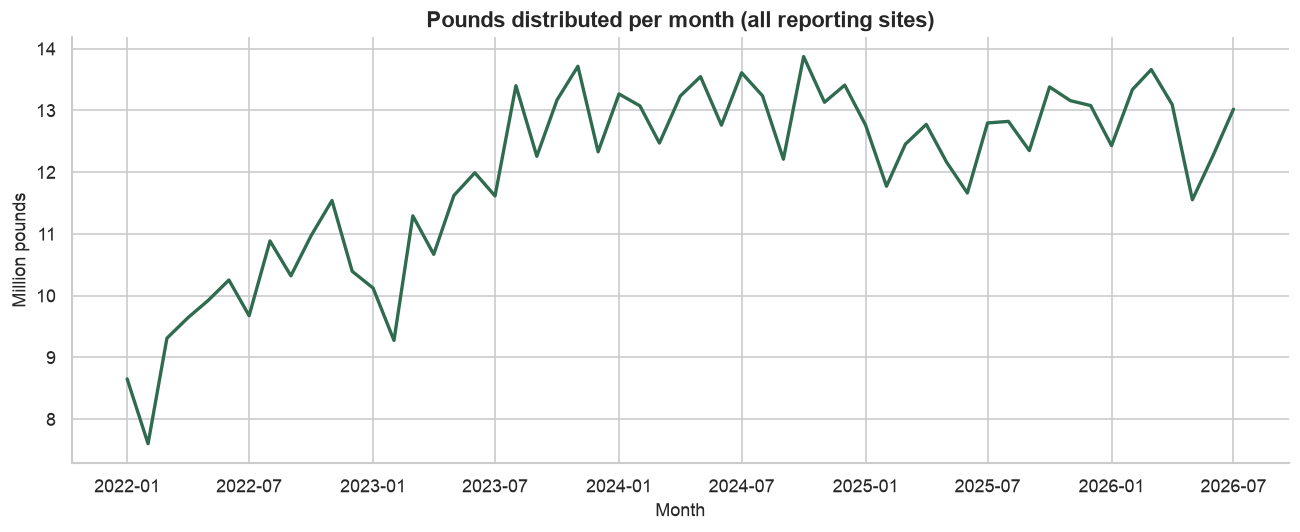

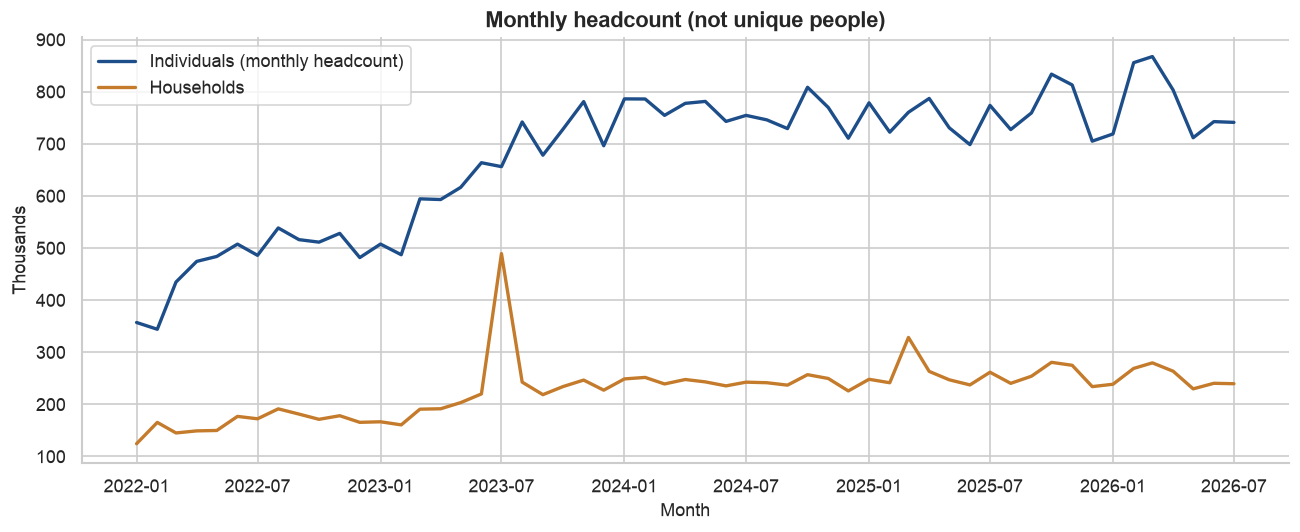

In [9]:
yearly = (
    fs.groupby("_Year")
    .agg(
        sites=("_id_site", "nunique"),
        months=("__ID", "size"),
        pounds=("PoundsReg", "sum"),
        households=("HouseholdsReg", "sum"),
        individuals=("IndividualsReg", "sum"),
        adults=("AdultsReg", "sum"),
        children=("ChildrenReg", "sum"),
        seniors=("SeniorsReg", "sum"),
    )
)
yearly["pounds_m"] = yearly["pounds"] / 1e6
yearly["indiv_m"] = yearly["individuals"] / 1e6
display(yearly.round(1))

monthly = (
    fs.groupby("DateForSearch")
    .agg(
        pounds=("PoundsReg", "sum"),
        households=("HouseholdsReg", "sum"),
        individuals=("IndividualsReg", "sum"),
        sites=("_id_site", "nunique"),
    )
    .reset_index()
)

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(monthly["DateForSearch"], monthly["pounds"] / 1e6, color=PALETTE["green"], lw=2)
ax.set_title("Pounds distributed per month (all reporting sites)")
ax.set_ylabel("Million pounds")
ax.set_xlabel("Month")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(monthly["DateForSearch"], monthly["individuals"] / 1e3, color=PALETTE["blue"], lw=2, label="Individuals (monthly headcount)")
ax.plot(monthly["DateForSearch"], monthly["households"] / 1e3, color=PALETTE["gold"], lw=2, label="Households")
ax.set_title("Monthly headcount (not unique people)")
ax.set_ylabel("Thousands")
ax.set_xlabel("Month")
ax.legend()
fig.tight_layout()
plt.show()

The **July 2023 household spike** is not real demand. Site `1197` (Waseca) reports **273,385 households** against 646 individuals that month — a two-order-of-magnitude typo that alone accounts for most of the jump. March 2025 has a similar (smaller) distortion from site `1304` (Ramsey-Suburbs, 83,909 households vs 13,735 individuals). Null `HouseholdsReg` when it is more than 5× `IndividualsReg`. A 20× cutoff misses Ramsey-Suburbs in March 2025 (6.1×, and the household field equals pounds).

In [10]:
suspect = fs[fs["HouseholdsReg"] > fs["IndividualsReg"].fillna(0) * 20]
print("Rows where households >> individuals:", len(suspect))
display(
    suspect.nlargest(8, "HouseholdsReg")[
        ["_id_site", "_Year", "_Month", "County", "HouseholdsReg", "IndividualsReg", "PoundsReg", "AgencyType"]
    ]
)

print("\nNumeric quality on core fields")
for c in ["PoundsReg", "HouseholdsReg", "IndividualsReg", "AdultsReg", "ChildrenReg", "SeniorsReg"]:
    s = fs[c]
    print(f"{c:16s}  neg={int((s<0).sum()):4d}  zero={int((s==0).sum()):5d}  NA={int(s.isna().sum()):5d}  max={s.max():,.0f}")

comp = fs[["AdultsReg", "ChildrenReg", "SeniorsReg", "IndividualsReg"]].dropna()
comp_sum = comp["AdultsReg"] + comp["ChildrenReg"] + comp["SeniorsReg"]
print("\nAdults+children+seniors == individuals (complete rows):",
      np.isclose(comp_sum, comp["IndividualsReg"]).mean())

Rows where households >> individuals: 13


,_id_site,_Year,_Month,County,HouseholdsReg,IndividualsReg,PoundsReg,AgencyType
9567,1197.0,2023,7,Waseca,273385.0,646.0,12053.0,Brick and Mortar Site
23694,1417.0,2025,11,Hubbard,6670.0,239.0,NaN,Brick and Mortar Site
17376,1219.0,2024,11,Hennepin-Minneapolis,2202.0,98.0,94686.0,Brick and Mortar Site
21740,1277.0,2025,7,Marshall,1590.0,49.0,NaN,Brick and Mortar Site
12827,13836.0,2024,1,McLeod,706.0,0.0,34900.0,Brick and Mortar Site
6928,14508.0,2023,2,Faribault,267.0,NaN,10250.0,Outreach Program
15261,14919.0,2024,7,Beltrami,243.0,NaN,983.0,Brick and Mortar Site
14416,14919.0,2024,5,Beltrami,119.0,NaN,1175.0,Brick and Mortar Site



Numeric quality on core fields
PoundsReg         neg=   4  zero= 1588  NA= 2235  max=994,394
HouseholdsReg     neg=   0  zero= 1581  NA= 2238  max=273,385
IndividualsReg    neg=   0  zero= 1579  NA= 2027  max=89,669
AdultsReg         neg=   0  zero= 1660  NA= 2062  max=49,756
ChildrenReg       neg=   0  zero= 2285  NA= 2186  max=36,915
SeniorsReg        neg=   1  zero= 2137  NA= 2236  max=10,065

Adults+children+seniors == individuals (complete rows): 1.0


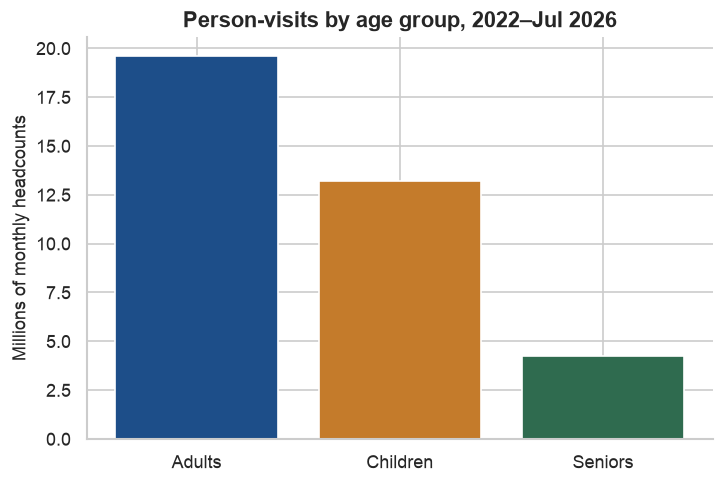

Adults            1.959017e+07
Children          1.322644e+07
Seniors           4.265281e+06
share_adults      5.280000e-01
share_children    3.570000e-01
share_seniors     1.150000e-01
dtype: float64


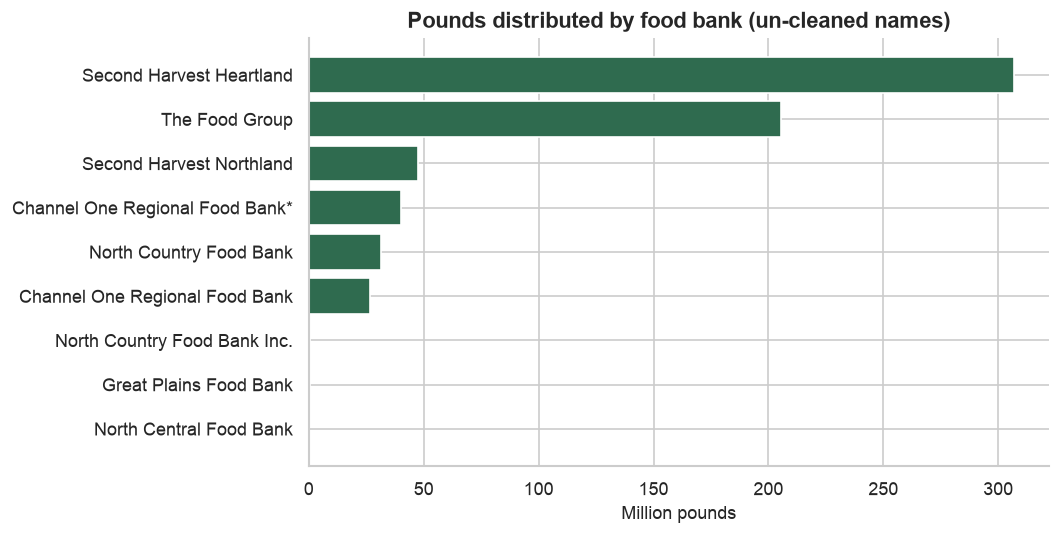


Name variants to merge before reporting:
  Channel One Regional Food Bank  vs  Channel One Regional Food Bank*
  North Country Food Bank  vs  North Country Food Bank Inc.


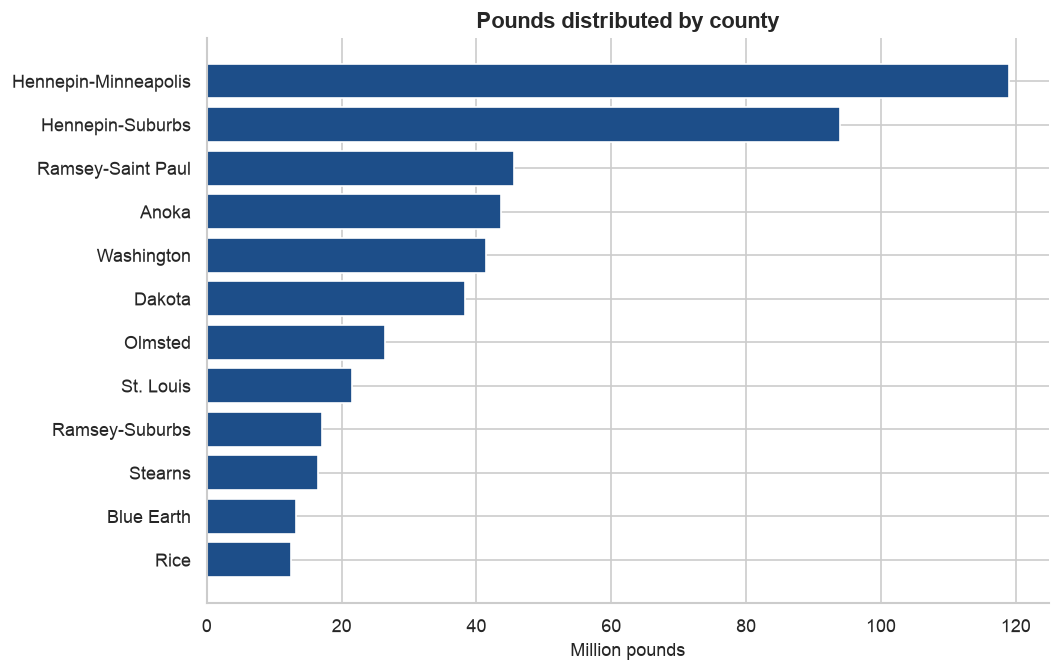

In [11]:
a, c, s = fs["AdultsReg"].sum(), fs["ChildrenReg"].sum(), fs["SeniorsReg"].sum()
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.bar(["Adults", "Children", "Seniors"], [a / 1e6, c / 1e6, s / 1e6], color=[PALETTE["blue"], PALETTE["gold"], PALETTE["green"]])
ax.set_title("Person-visits by age group, 2022–Jul 2026")
ax.set_ylabel("Millions of monthly headcounts")
fig.tight_layout()
plt.show()
print(pd.Series({"Adults": a, "Children": c, "Seniors": s, "share_adults": a/(a+c+s), "share_children": c/(a+c+s), "share_seniors": s/(a+c+s)}).round(3))

fb = fs.groupby("FoodBank")["PoundsReg"].sum().sort_values(ascending=False) / 1e6
barh(fb, "Pounds distributed by food bank (un-cleaned names)", "Million pounds", PALETTE["green"], n=10)
print("\nName variants to merge before reporting:")
print("  Channel One Regional Food Bank  vs  Channel One Regional Food Bank*")
print("  North Country Food Bank  vs  North Country Food Bank Inc.")

county = fs.groupby("County")["PoundsReg"].sum().sort_values(ascending=False) / 1e6
barh(county, "Pounds distributed by county", "Million pounds", PALETTE["blue"], n=12)

Pounds / individual (dictionary: calculate yourself)


,PoundsPerIndiv
count,24681.000000
mean,23.460840
std,16.840931
min,-26.000000
5%,6.000000
50%,21.000000
95%,47.000000
99%,67.000000
max,966.000000


Individuals per household


,IndividualsPerHH
count,24468.000000
mean,2.849926
std,1.474112
min,0.000000
5%,1.000000
50%,3.000000
95%,5.000000
99%,6.000000
max,100.000000


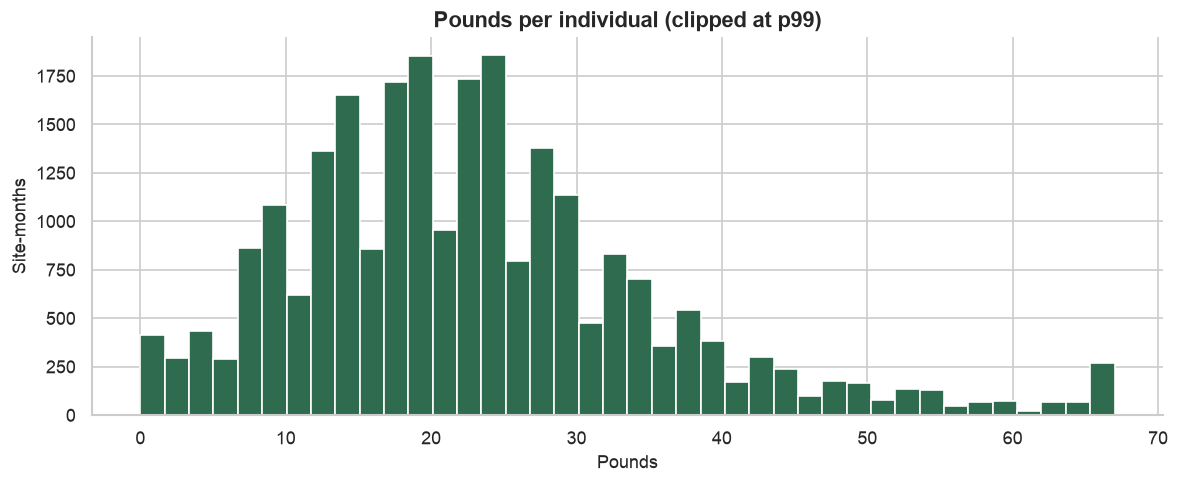

In [12]:
print("Pounds / individual (dictionary: calculate yourself)")
display(fs["PoundsPerIndiv"].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).to_frame())
print("Individuals per household")
display(fs["IndividualsPerHH"].describe(percentiles=[0.05, 0.5, 0.95, 0.99]).to_frame())

fig, ax = plt.subplots(figsize=(10, 4.2))
vals = fs["PoundsPerIndiv"].dropna().clip(lower=0, upper=fs["PoundsPerIndiv"].quantile(0.99))
ax.hist(vals, bins=40, color=PALETTE["green"], edgecolor="white")
ax.set_title("Pounds per individual (clipped at p99)")
ax.set_xlabel("Pounds")
ax.set_ylabel("Site-months")
fig.tight_layout()
plt.show()

**Takeaways**

- Pounds rose from **119M (2022)** to a peak of **158M (2024)**, then eased to **151M (2025)**. 2026 is on a similar annualized pace (~153M).
- Person-visits grew faster than pounds (**+61%** individuals 2022→2025 vs **+27%** pounds), so **pounds per person fell**.
- Age mix is stable: ~53% adults, ~36% children, ~11% seniors.
- Second Harvest Heartland and The Food Group account for the large majority of pounds. Merge Channel One / North Country name variants before ranking.
- Metro counties (Hennepin, Ramsey, Anoka, Washington, Dakota) dominate volume.
- ~1,580 site-months report zeros; 4 rows have negative pounds; 34 sites do not join to `Organization`.

## 4. Market Bucks (`marketbucksUsage`)

13,573 market-day rows at **155 sites**, January 2022 – July 2026. Every `_id_site` joins to `Organization`. Market Bucks match SNAP/EBT (and SUN Bucks) **up to $10 per visit** at participating farmers markets. Produce Bucks are a separate incentive layer; RC* fields are Ramsey County–specific and mostly unused.

**Do not compute a redemption rate from column sums.** `SNAPRedeemed` is missing on 3,210 rows and `MBRedeemed` on 3,424. Naive sums make redemption look like it exceeds distribution. Restrict to rows where both sides are present, and even then ~28% of SNAP rows and ~36% of MB rows have redeemed > distributed (tokens likely redeem on a later date than they were issued).

In [13]:
print("Sites:", mb["_id_site"].nunique(), "| late entries:", int((mb["isLateEntry"]==1).sum()))
print("Site × date duplicate rows:", int(mb.duplicated(["_id_site", "Dated"]).sum()),
      "(often two valid sessions the same day — sum, don't drop)")
print("Join to Organization:", f"{mb['_id_site'].isin(org_ids).mean():.1%}")

money = [
    "SNAPDistributed", "SNAPRedeemed", "MBDistributed", "MBRedeemed",
    "PBDistributed", "PBRedeemed", "GiftCerts", "RCMBDistributed", "RCMBRedeemed",
]
display(mb[money + ["Customers", "Transactions"]].describe().T.round(2))
print("\nColumn sums (for scale only — not redemption rates)")
print(mb[money + ["Customers", "Transactions"]].sum().round(2))

Sites: 155 | late entries: 215
Site × date duplicate rows: 279 (often two valid sessions the same day — sum, don't drop)
Join to Organization: 100.0%


,count,mean,std,min,25%,50%,75%,max
SNAPDistributed,12951.0,219.58,476.10,0.0,30.0,92.0,242.0,10169.0
SNAPRedeemed,10363.0,237.54,951.75,0.0,21.0,73.0,199.0,29545.0
MBDistributed,12689.0,126.39,275.44,0.0,20.0,50.0,140.0,17944.0
MBRedeemed,10149.0,149.84,753.01,0.0,10.0,30.0,95.0,22149.0
PBDistributed,11328.0,127.18,276.26,0.0,18.0,50.0,140.0,16091.0
PBRedeemed,9077.0,143.96,763.88,0.0,8.0,28.0,91.0,26441.0
GiftCerts,5830.0,0.15,2.39,0.0,0.0,0.0,0.0,82.0
RCMBDistributed,3915.0,1.05,10.13,0.0,0.0,0.0,0.0,240.0
RCMBRedeemed,3863.0,0.91,10.40,0.0,0.0,0.0,0.0,328.0
Customers,10516.0,2.38,16.49,0.0,0.0,1.0,2.0,1236.0



Column sums (for scale only — not redemption rates)
SNAPDistributed    2843781.16
SNAPRedeemed       2461614.40
MBDistributed      1603803.84
MBRedeemed         1520733.32
PBDistributed      1440712.13
PBRedeemed         1306681.11
GiftCerts              899.00
RCMBDistributed       4109.00
RCMBRedeemed          3502.12
Customers            24988.00
Transactions        194559.00
dtype: float64


,SNAPDistributed,MBDistributed,PBDistributed,Customers,Transactions
year,,,,,
2022,614657.0,320167.0,309852.0,6418.0,36924.0
2023,750706.0,334681.0,339362.0,3632.0,49302.0
2024,643213.0,402067.0,408026.0,8531.0,46748.0
2025,597692.0,405204.0,383472.0,4057.0,44572.0
2026,237514.0,141685.0,0.0,2350.0,17013.0


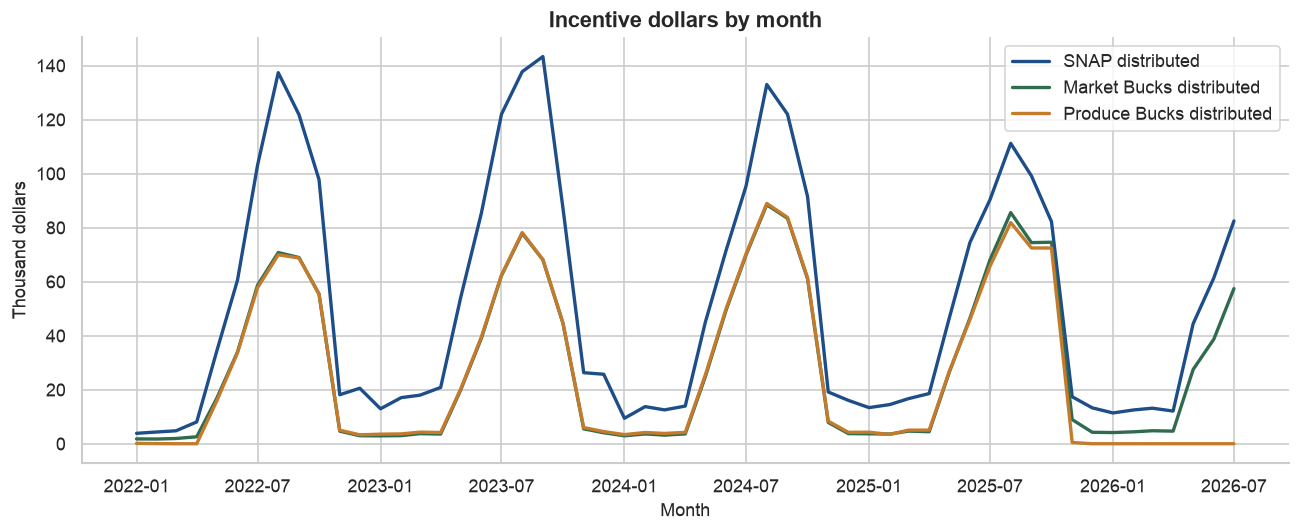

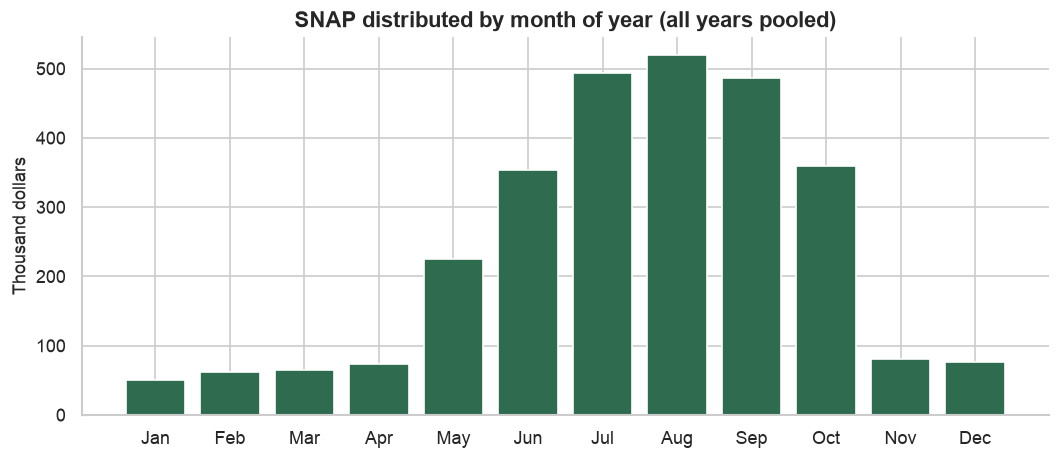

In [14]:
mb = mb.copy()
mb["year"] = mb["Dated"].dt.year
mb["ym"] = mb["Dated"].dt.to_period("M").dt.to_timestamp()
yearly_mb = mb.groupby("year")[["SNAPDistributed", "MBDistributed", "PBDistributed", "Customers", "Transactions"]].sum()
display(yearly_mb.round(0))

monthly_mb = mb.groupby("ym")[["SNAPDistributed", "MBDistributed", "PBDistributed"]].sum()
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(monthly_mb.index, monthly_mb["SNAPDistributed"] / 1e3, color=PALETTE["blue"], lw=2, label="SNAP distributed")
ax.plot(monthly_mb.index, monthly_mb["MBDistributed"] / 1e3, color=PALETTE["green"], lw=2, label="Market Bucks distributed")
ax.plot(monthly_mb.index, monthly_mb["PBDistributed"] / 1e3, color=PALETTE["gold"], lw=2, label="Produce Bucks distributed")
ax.set_title("Incentive dollars by month")
ax.set_ylabel("Thousand dollars")
ax.set_xlabel("Month")
ax.legend()
fig.tight_layout()
plt.show()

season = mb.assign(month=mb["Dated"].dt.month).groupby("month")["SNAPDistributed"].sum()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(season.index, season.values / 1e3, color=PALETTE["green"])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_title("SNAP distributed by month of year (all years pooled)")
ax.set_ylabel("Thousand dollars")
fig.tight_layout()
plt.show()

In [15]:
both_snap = mb[mb["SNAPDistributed"].notna() & mb["SNAPRedeemed"].notna()]
both_mb = mb[mb["MBDistributed"].notna() & mb["MBRedeemed"].notna()]
print("SNAP redeemed/distributed on complete rows:",
      f"{both_snap['SNAPRedeemed'].sum() / both_snap['SNAPDistributed'].sum():.1%}",
      f"(n={len(both_snap):,}; redeemed>dist on {(both_snap['SNAPRedeemed'] > both_snap['SNAPDistributed'] + 0.01).mean():.1%})")
print("MB redeemed/distributed on complete rows:",
      f"{both_mb['MBRedeemed'].sum() / both_mb['MBDistributed'].sum():.1%}",
      f"(n={len(both_mb):,}; redeemed>dist on {(both_mb['MBRedeemed'] > both_mb['MBDistributed'] + 0.01).mean():.1%})")

mbj = mb.merge(
    orgs[["__ID", "AgencyType", "City", "Region", "FindHelpMapCategory", "ActiveInactive"]],
    left_on="_id_site",
    right_on="__ID",
    how="left",
)
print("\nSNAP $ by agency type")
display(mbj.groupby("AgencyType")["SNAPDistributed"].sum().sort_values(ascending=False).round(0).to_frame())
print("SNAP $ by region")
display(mbj.groupby("Region")["SNAPDistributed"].sum().sort_values(ascending=False).round(0).to_frame())

site_vol = (
    mbj.groupby(["_id_site", "City", "AgencyType"], dropna=False)["SNAPDistributed"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
print("Top 10 sites by SNAP distributed")
display(site_vol.round(0))

SNAP redeemed/distributed on complete rows: 99.2% (n=10,000; redeemed>dist on 28.1%)
MB redeemed/distributed on complete rows: 118.7% (n=9,703; redeemed>dist on 36.2%)

SNAP $ by agency type


,SNAPDistributed
AgencyType,
Farmers Market,2843451.0
Food Bank,0.0


SNAP $ by region


,SNAPDistributed
Region,
Twin Cities 7-Metro,2112874.0
Southern Minnesota,295066.0
Northern Minnesota,260310.0
Central Minnesota,128617.0


Top 10 sites by SNAP distributed


,_id_site,City,AgencyType,SNAPDistributed
0,14287,Minneapolis,Farmers Market,421033.0
1,14261,St. Paul,Farmers Market,359488.0
2,14293,Minneapolis,Farmers Market,240749.0
3,14237,New Hope,Farmers Market,206491.0
4,14901,NaN,Farmers Market,153307.0
5,14300,Rochester,Farmers Market,129150.0
6,14243,Burnsville,Farmers Market,105499.0
7,14268,Jacobson,Farmers Market,65188.0
8,14286,Minneapolis,Farmers Market,52024.0
9,14259,Minneapolis,Farmers Market,48481.0


**Takeaways**

- About **$2.84M SNAP**, **$1.60M Market Bucks**, and **$1.44M Produce Bucks** were distributed over the extract window.
- SNAP at markets **peaked in 2023 ($751k)** and has drifted down; Market Bucks dollars stayed flat-to-up through 2025. Produce Bucks drop to $0 in 2026 year-to-date — worth confirming whether the program paused or reporting changed.
- Strong **summer seasonality**, as expected for outdoor markets; some winter markets keep a floor in Jan–Mar.
- Twin Cities 7-Metro is the SNAP volume center. Top sites are Minneapolis / St. Paul / New Hope / Rochester farmers markets.
- 151 of 185 farmers-market organizations appear in usage; the rest may be inactive, new, or not in the Market Bucks program.

## 5. SNAP helpline (`Incoming Call`)

49,727 contacts. Dates run 2022-02-23 to 2026-07-31, but **2022 is not usable** (41 rows, all SNAP Rx). Volume is continuous from January 2023.

`CallMethod == "SNAP Rx"` and `PrimaryReasonForCall == "SNAP Rx"` agree on 99.996% of rows — it is both a channel and a reason. SNAP Rx is a clinic-referral enrollment workflow (HealthPartners, WIC sites, Hennepin Healthcare, Essentia, etc.).

In [16]:
print("Primary key unique?", calls["__ID"].is_unique, "| duplicate IDs:", int(calls["__ID"].duplicated().sum()))
print("\nCall method")
display(calls["CallMethod"].value_counts(dropna=False).to_frame("n"))
print("Primary reason")
display(calls["PrimaryReasonForCall"].value_counts(dropna=False).head(20).to_frame("n"))
print("SNAP status")
display(calls["SNAP Status"].value_counts(dropna=False).to_frame("n"))
print("Region")
display(calls["Region"].value_counts(dropna=False).to_frame("n"))
print("Follow-up needed / days")
display(calls["FollowUpNeeded"].value_counts(dropna=False).to_frame("n"))
display(calls["FollowUpNeededDays"].value_counts(dropna=False).to_frame("n"))

Primary key unique? False | duplicate IDs: 2

Call method


,n
CallMethod,
SNAP Rx,19096
Live Call,17359
Voice Mail,7347
Email,4193
Chat Ticket,1048
Chat,374
Text,200
Partner Referral,110


Primary reason


,n
PrimaryReasonForCall,
SNAP Rx,19094
Food Shelf,8108
Case-Specific Issues,4686
Eligibility Requirements,3356
Other,2679
EBT Card,2450
SUN Bucks,1812
Application Status,1602
Application Assistance,1231


SNAP status


...

Region


,n
Region,
Twin Cities 7-Metro,28523
NaN,15330
Central Minnesota,1885
Unknown/Out Of State,1814
Southern Minnesota,1261
Northern Minnesota,914


Follow-up needed / days


,n
FollowUpNeeded,
NaN,35725
Other,13543
2 Weeks,362
1 Day,86
6 Weeks,8
2 Days,3


,n
FollowUpNeededDays,
NaN,35725
0.0,13632
14.0,362
42.0,8


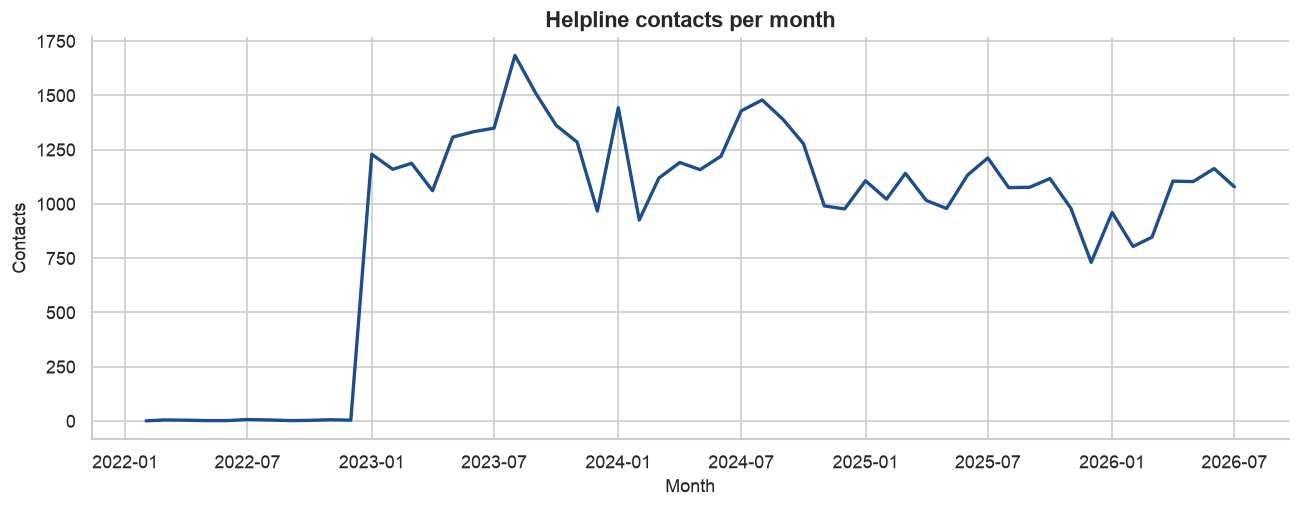

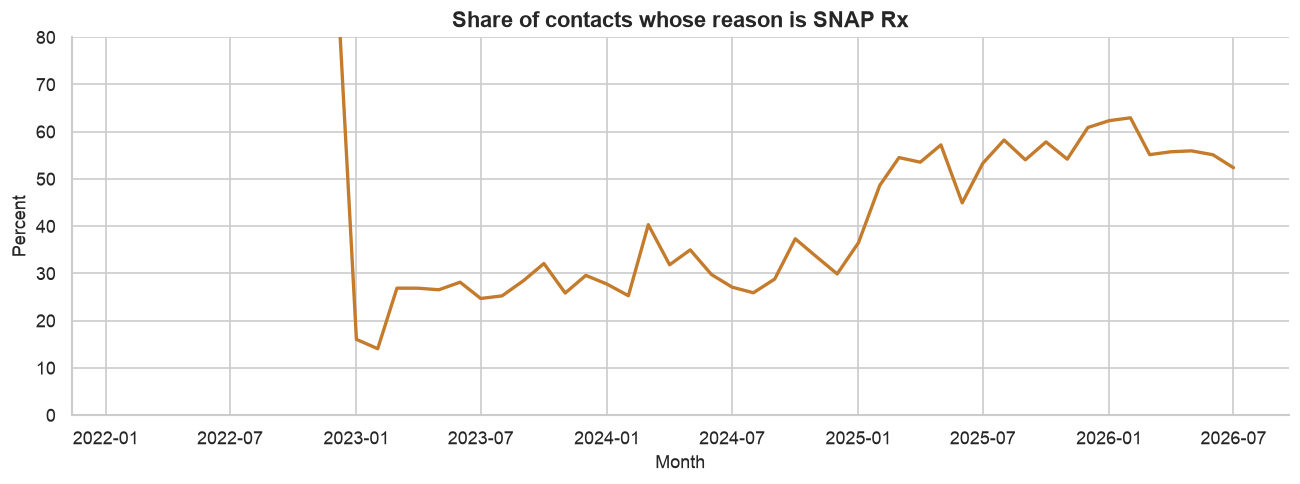

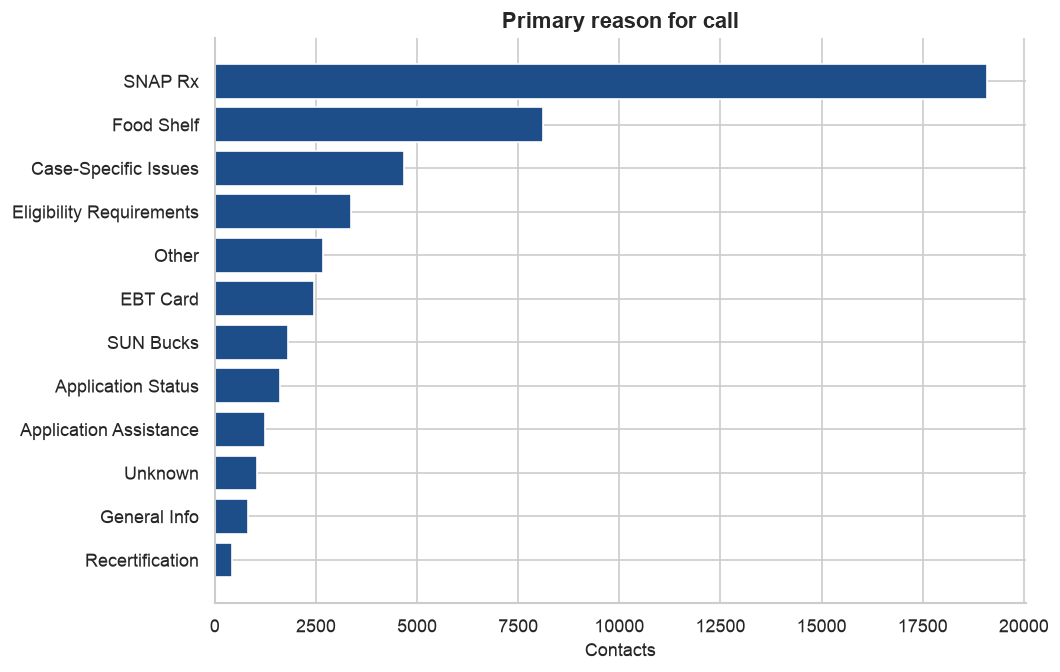

In [17]:
calls = calls.copy()
calls["ym"] = calls["Date"].dt.to_period("M").dt.to_timestamp()
vol = calls.groupby("ym").size()

fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(vol.index, vol.values, color=PALETTE["blue"], lw=2)
ax.set_title("Helpline contacts per month")
ax.set_ylabel("Contacts")
ax.set_xlabel("Month")
fig.tight_layout()
plt.show()

snaprx = calls.assign(is_rx=(calls["PrimaryReasonForCall"] == "SNAP Rx").astype(int))
share = snaprx.groupby("ym")["is_rx"].mean()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(share.index, share.values * 100, color=PALETTE["gold"], lw=2)
ax.set_title("Share of contacts whose reason is SNAP Rx")
ax.set_ylabel("Percent")
ax.set_xlabel("Month")
ax.set_ylim(0, 80)
fig.tight_layout()
plt.show()

reason = calls["PrimaryReasonForCall"].fillna("(missing)").value_counts().head(12)
barh(reason, "Primary reason for call", "Contacts", PALETTE["blue"], n=12)

Weekday mix (almost no weekend coverage)


,n
Date,
Monday,10195
Tuesday,11549
Wednesday,10990
Thursday,9386
Friday,7516
Saturday,46
Sunday,45


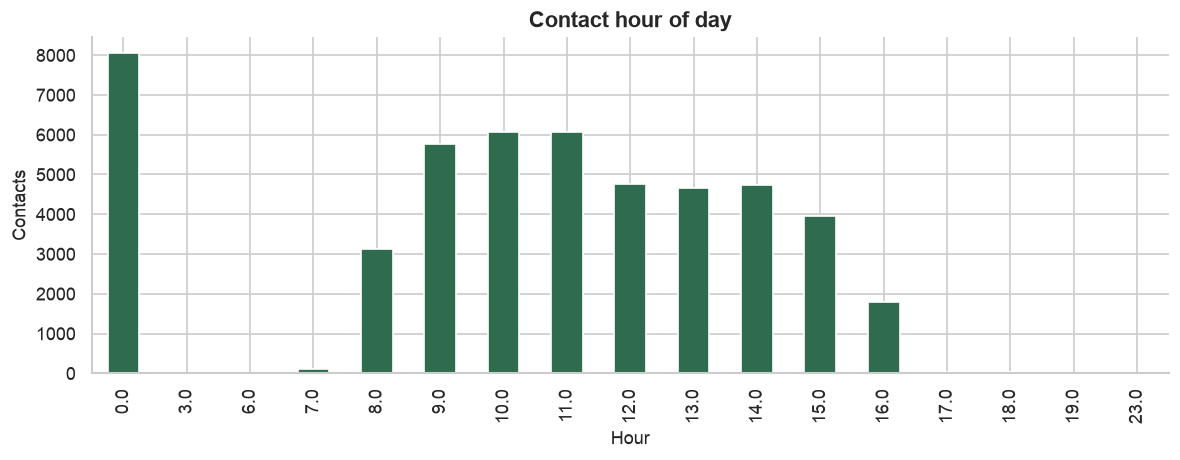

Call length


,n
CallLength,
1-5 minutes,25947
NaN,21504
5-10 minutes,1837
11-15 minutes,321
16-20 minutes,61
21+ minutes,57


Call answered


,n
Call Answered,
NaN,22670
No Answer,13507
1st,8817
2nd,4099
3rd,553
4th,66
1st Call,12
2nd Call,3


Household size on the ticket


,NumberInHouse
count,49710.000000
mean,1.215429
std,0.766721
min,1.000000
50%,1.000000
90%,2.000000
99%,5.000000
max,14.000000


Follow-up 1 complete: 16670 | follow-up 2 complete: 874
Application mailed = Yes: 639


In [18]:
print("Weekday mix (almost no weekend coverage)")
display(calls["Date"].dt.day_name().value_counts().reindex(
    ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
).to_frame("n"))

hours = calls["CallTime"].apply(lambda t: getattr(t, "hour", np.nan))
fig, ax = plt.subplots(figsize=(10, 4))
hours.value_counts().sort_index().plot(kind="bar", ax=ax, color=PALETTE["green"])
ax.set_title("Contact hour of day")
ax.set_xlabel("Hour")
ax.set_ylabel("Contacts")
fig.tight_layout()
plt.show()

print("Call length")
display(calls["CallLength"].value_counts(dropna=False).to_frame("n"))
print("Call answered")
display(calls["Call Answered"].value_counts(dropna=False).to_frame("n"))
print("Household size on the ticket")
display(calls["NumberInHouse"].describe(percentiles=[0.5, 0.9, 0.99]).to_frame())
print("Follow-up 1 complete:", int((calls["isFollowup1Complete"]==1).sum()),
      "| follow-up 2 complete:", int((calls["isFollowup2Complete"]==1).sum()))
print("Application mailed = Yes:", int((calls["Application Mailed"]=="Yes").sum()))

In [19]:
print("Top counties (raw labels — includes typos and metro splits)")
display(calls["County"].value_counts(dropna=False).head(20).to_frame("n"))

print("\nTop SNAP Rx referral sources")
display(calls.loc[calls["PrimaryReasonForCall"]=="SNAP Rx", "Referral Source"]
        .value_counts(dropna=False).head(12).to_frame("n"))

print("How did you hear about us? (98% missing)")
display(calls["HowHear"].value_counts(dropna=False).head(10).to_frame("n"))

miss = missing_table(calls)
print("\nFields with >30% missing")
display(miss.loc[miss["pct_missing"] > 30, ["n_missing", "pct_missing", "n_unique"]])

Top counties (raw labels — includes typos and metro splits)


,n
County,
NaN,15159
Hennepin,10102
Ramsey,9438
Hennepin-Suburbs,2619
Dakota,2135
Anoka,1483
Ramsey-Suburbs,1132
(Unknown),1106
Washington,794



Top SNAP Rx referral sources


,n
Referral Source,
Health Partners,6009
Health Partners Misc,1612
Rice Street WIC,1218
East Side WIC,1037
Suburban Square WIC,886
Midway WIC,655
Hennepin Healthcare- Csc Peds Primary Cl,624
Essentia,569
La Clinica WIC,379


How did you hear about us? (98% missing)


,n
HowHear,
NaN,48652
Online,691
Word of Mouth,215
MNFoodHelper.org,86
Unknown,23
Local Food Shelf,20
County Office,17
SNAP Campaign Materials,8
Other,7



Fields with >30% missing


,n_missing,pct_missing,n_unique
SNAPApplicationhelp,49702,99.9,2
FollowupDate2,49068,98.7,119
isFollowup2Complete,48853,98.2,1
HowHear,48652,97.8,11
BestContactMethod,47154,94.8,27
BridgeToBenefitsScreen,44890,90.3,3
Application Mailed,44448,89.4,2
zzModificationTSNotServer,42595,85.7,5961
FollowUpNeeded,35725,71.8,5
FollowUpNeededDays,35725,71.8,3


**Takeaways**

- After the 2023 start, volume is roughly **1,000–1,500 contacts/month**, with a dip each December.
- **SNAP Rx is now the majority channel** (about 38% overall; 25% in 2023 → 31% in 2024 → 53% in 2025 → 57% in 2026 YTD), driven by HealthPartners, WIC clinics, and health-system referrals. Food-shelf navigation is the #2 reason (8,108). Use `PrimaryReasonForCall`, not the `isSNAPRx` flag — the flag undercounts in 2023 (reason 25% vs flag ~4%).
- Geography is Twin Cities–heavy (Hennepin + Ramsey dominate). 30% of contacts have no county; remaining labels include typos (`hennipen`, `ramesy`, `sterns`) and inconsistent metro splits (`Hennepin` vs `Hennepin-Suburbs`).
- Operations: weekday daytime only; most timed calls are 1–5 minutes; 13,507 marked `No Answer`. First follow-up is completed on 16,670 tickets; a second follow-up is rare (874), matching the dictionary.
- `NumberInHouse` averages **1.22** — that is the party on the ticket, not a food-shelf household size. Do not join it naively to `IndividualsPerHH` in FSStats.
- `HowHear`, `BestContactMethod`, `BridgeToBenefitsScreen`, and `SNAPApplicationhelp` are too sparse to use.

## 6. Cross-dataset relationships

The four tables connect through **organization IDs** and **place names**, not through a person ID. You cannot follow one household from the helpline to a food shelf to a farmers market.

In [20]:
print("FSStats sites matching Organization:", f"{fs['_id_site'].isin(org_ids).mean():.1%} of rows")
print("Market Bucks sites matching Organization:", f"{mb['_id_site'].isin(org_ids).mean():.1%} of rows")
print("FSStats id_agency matching Organization:",
      f"{fs['id_agency'].dropna().isin(org_ids).mean():.1%} of non-null rows",
      f"(null id_agency: {fs['id_agency'].isna().mean():.1%})")

def norm_county(s):
    return (
        s.dropna().astype(str).str.strip().str.lower()
        .str.replace(r"\s+", " ", regex=True)
        .str.replace("saint louis", "st. louis")
        .str.replace("st louis", "st. louis")
    )

cc, fc, oc = set(norm_county(calls["County"])), set(norm_county(fs["County"])), set(norm_county(orgs["County"]))
print(f"\nCounty label sets — calls {len(cc)}, FSStats {len(fc)}, orgs {len(oc)}")
print(f"  overlap calls ∩ FSStats: {len(cc & fc)}")
print(f"  overlap FSStats ∩ orgs:  {len(fc & oc)}")
print("  call labels not in FSStats (typos / extras):")
print(sorted(cc - fc)[:25])

# Metro concentration vs helpline
fs_pounds_region = (
    fs.merge(orgs[["__ID", "SuperRegion"]], left_on="_id_site", right_on="__ID", how="left")
    .groupby("SuperRegion")["PoundsReg"].sum()
)
print("\nPounds by SuperRegion (via org join)")
display((fs_pounds_region / 1e6).round(1).to_frame("million_pounds"))
print("Helpline contacts by Region")
display(calls["Region"].value_counts(dropna=False).to_frame("n"))

FSStats sites matching Organization: 99.9% of rows
Market Bucks sites matching Organization: 100.0% of rows
FSStats id_agency matching Organization: 95.7% of non-null rows (null id_agency: 22.7%)

County label sets — calls 110, FSStats 90, orgs 90
  overlap calls ∩ FSStats: 90
  overlap FSStats ∩ orgs:  90
  call labels not in FSStats (typos / extras):
['( out of state )', '(unknown)', 'aanoka', 'cottonwood/brown', 'dakota county', 'dakotadakota', 'filmorefillmore', 'h', 'hennepin county', 'hennhennepin', 'hennipen', 'olmsted county', 'ramesy', 'rasmey', 'rroseau', 'stearns county', 'sterns', 'usa', 'wilkin', 'wright county']

Pounds by SuperRegion (via org join)


,million_pounds
SuperRegion,
Metro,413.0
Non-Metro,221.0


Helpline contacts by Region


,n
Region,
Twin Cities 7-Metro,28523
NaN,15330
Central Minnesota,1885
Unknown/Out Of State,1814
Southern Minnesota,1261
Northern Minnesota,914


## 7. Data-quality register

Use this as a cleaning checklist before modeling.

| Issue | Where | What to do |
|---|---|---|
| 24 empty deprecated columns | FSStats Extra/Produce/Holiday, Misc, People, Snacks | Drop |
| `*Total` duplicates `*Reg` | FSStats | Keep `*Reg` only |
| Household outliers | FSStats Jul 2023 Waseca; Mar 2025 Ramsey-Suburbs | Null `HouseholdsReg` when it exceeds 5× individuals |
| Negative pounds (4 rows) | FSStats `PoundsReg` | Drop or abs() after review |
| Duplicate site-months (43 keys) | FSStats | Inspect: some are blank copies, some look like split programs — do not blindly drop |
| 34 sites missing from Organization | FSStats `_id_site` | Left-join and keep an “unmatched” bucket |
| Food-bank name variants | FSStats `FoodBank` | Normalize Channel One*, North Country Inc. |
| Fractional org IDs | Organization / FSStats | Keep as floats |
| Zip codes in `State` | Organization | Recode; strip `MN\n` |
| Duplicate market-days | Market Bucks | Sum metrics by (`_id_site`, `Dated`) |
| Redemption > distribution | Market Bucks | Analyze at site-month with carryover, not row-level rates |
| Produce Bucks = 0 in 2026 YTD | Market Bucks | Confirm program status before concluding it ended |
| 2 duplicate call IDs | Incoming Call | Drop exact duplicates |
| 2022 call volume (~41 rows) | Incoming Call | Start helpline time series in 2023-01 |
| County typos and metro splits | Incoming Call vs FSStats | Build a county crosswalk (`Hennepin` vs `Hennepin-Minneapolis` / `Hennepin-Suburbs`) |
| 30% missing county / SNAP status | Incoming Call | Don’t drop; treat as unknown |
| `HowHear` 98% missing | Incoming Call | Ignore for inference |
| Static legislative districts | Organization / FSStats | Do not trend across redistricting |
| No person-level key across tables | All | Analyze at site / county / month, not customer journey |

## 8. What this suggests for the challenge

The Food Group asked student teams to work on **food insecurity** with these operational systems. The EDA points to a few high-leverage questions (not answers yet):

1. **Demand is up more than supply per person.** Food-shelf person-visits grew ~61% from 2022 to 2025 while pounds grew ~27%. Where did pounds per person fall the most — metro vs Greater Minnesota, TEFAP vs not, SuperShelf vs not?
2. **The helpline is becoming a clinical referral desk.** SNAP Rx now accounts for most contacts. That is a different client mix than “I need a food shelf today.” Food-shelf calls (8k) and farmers-market calls (262) are the bridge to the other two datasets.
3. **Market Bucks SNAP dollars peaked in 2023.** Incentive (MB) dollars held up better than SNAP spent at markets. Is that market participation, SNAP caseload, awareness, or winter-market coverage?
4. **Geography is lopsided.** Twin Cities counties dominate pounds and calls. Greater Minnesota has more *organizations* but less reported volume — a coverage vs need question if you bring in census poverty / SNAP participation later.
5. **You cannot build a person-level funnel** from these files. The honest grain is **county × month** or **site × month**, with the helpline joined on cleaned county names.

Recommended next steps after this EDA:

- Build a county crosswalk and a monthly panel (FSStats + Market Bucks + calls).
- Winsorize household outliers; drop deprecated columns; normalize food-bank names.
- Add external ACS / SNAP caseload / unemployment if the division expects a model.
- Decide the outcome: pounds, person-visits, helpline demand, or Market Bucks take-up — they tell different stories.

## 9. Field subsets worth keeping

Copy-paste starting points for later notebooks.

In [21]:
FS_KEEP = [
    "__ID", "_id_site", "id_agency", "_id_bank", "_Year", "_Month", "DateForSearch",
    "AdultsReg", "ChildrenReg", "SeniorsReg", "HouseholdsReg", "IndividualsReg", "PoundsReg",
    "County", "FoodBank", "AgencyType",
]
ORG_KEEP = [
    "__ID", "City", "State", "Zip", "County", "Region", "SuperRegion",
    "AgencyType", "ActiveInactive", "isActive", "isDistributionSite",
    "TefapStatus", "isTEFAPEligible", "FindHelpMapCategory", "isFindHelpMap",
    "z12MoAverage_Pounds", "z12MoAverage_House", "z12MoAverage_Indiv",
    "zcountDaysOperations", "block_geoid",
]
MB_KEEP = [
    "_ID", "_id_site", "Dated",
    "SNAPDistributed", "SNAPRedeemed", "MBDistributed", "MBRedeemed",
    "PBDistributed", "PBRedeemed", "Customers", "Transactions", "isLateEntry",
]
CALL_KEEP = [
    "__ID", "Date", "CallTime", "CallLength", "CallMethod", "Call Answered",
    "County", "Region", "NumberInHouse", "PrimaryReasonForCall", "SNAP Status",
    "isSNAPRx", "Referral Source", "FollowUpNeeded", "FollowUpNeededDays",
    "isFollowup1Complete", "isFollowup2Complete",
]

print("FS keep", len(FS_KEEP), "/", fs.shape[1])
print("Org keep", len(ORG_KEEP), "/", orgs.shape[1])
print("MB keep", len(MB_KEEP), "/", mb.shape[1])
print("Call keep", len(CALL_KEEP), "/", calls.shape[1])

FS keep 16 / 58
Org keep 20 / 68
MB keep 12 / 21
Call keep 17 / 32


## 10. Cleaning, and what changes

Rules from the register above, applied to the four extracts. Cleaned tables are written to `cleaned/`. Counts are not imputed, and unmatched sites are kept.

Households are set to missing when they are more than **5×** individuals. A 20× cutoff would leave March 2025 Ramsey-Suburbs in the series: 83,909 households against 13,735 individuals, with the household field equal to pounds. Age groups already match `IndividualsReg` on every complete row, so person counts are left as reported.


In [22]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from clean_extracts import MN_COUNTIES, clean_all, load_raw, write_cleaned

PALETTE = {"green": "#2F6B4F", "blue": "#1D4E89", "gold": "#C47B2B", "red": "#B42318"}

raw = load_raw()
cleaned = clean_all(raw)
write_cleaned(cleaned)

fs, calls, mb = raw["fs"], raw["calls"], raw["mb"]
f2, c2, m2, mm = cleaned["fs"], cleaned["calls"], cleaned["mb"], cleaned["mb_month"]

calls_base = (
    calls.sort_values(["__ID", "zzCreationTS"], na_position="last")
    .drop_duplicates("__ID", keep="first")
)
calls_base = calls_base.loc[calls_base["Date"] >= "2023-01-01"].copy()

def year_metrics(df, year):
    part = df.loc[df["_Year"] == year]
    pounds = part["PoundsReg"].sum()
    people = part["IndividualsReg"].sum()
    return {
        "pounds_m": pounds / 1e6,
        "households": part["HouseholdsReg"].sum(),
        "individuals_m": people / 1e6,
        "lb_per_person": pounds / people,
    }

yearly_rows = []
for year in sorted(fs["_Year"].unique()):
    before = year_metrics(fs, year)
    after = year_metrics(f2, year)
    yearly_rows.append({
        "year": int(year),
        "pounds_m_raw": round(before["pounds_m"], 2),
        "pounds_m_clean": round(after["pounds_m"], 2),
        "households_raw": int(round(before["households"])),
        "households_clean": int(round(after["households"])),
        "individuals_m_raw": round(before["individuals_m"], 3),
        "individuals_m_clean": round(after["individuals_m"], 3),
        "lb_per_person_raw": round(before["lb_per_person"], 2),
        "lb_per_person_clean": round(after["lb_per_person"], 2),
    })
yearly = pd.DataFrame(yearly_rows).set_index("year")

print(f"Wrote {Path('cleaned').resolve()}")
print(
    f"Food shelves  {len(fs):,} rows × {fs.shape[1]} cols"
    f"  →  {len(f2):,} rows × {f2.shape[1]} cols"
)
print(f"Helpline      {len(calls):,} rows  →  {len(c2):,} rows (drop 2 duplicate IDs and 41 contacts from 2022)")
print(f"Market days   {len(mb):,} rows  →  {len(m2):,} site-days, {len(mm):,} site-months")
print("\nFood-shelf duplicate actions")
display(f2["dup_action"].value_counts().to_frame("site_months"))
print(
    "Households set to missing:", int(f2["hh_quarantined"].sum()),
    "| negative pounds set to missing:", int(f2["pounds_quarantined"].sum()),
)
print("\nYearly totals. 2026 runs through July.")
display(yearly)


Wrote /Users/clever2226/Downloads/MinneMUDAC/cleaned
Food shelves  28,287 rows × 58 cols  →  28,243 rows × 29 cols
Helpline      49,727 rows  →  49,685 rows (drop 2 duplicate IDs and 41 contacts from 2022)
Market days   13,573 rows  →  13,294 site-days, 2,948 site-months

Food-shelf duplicate actions


,site_months
dup_action,
kept,28200
summed_split,26
dropped_exact_copy,9
dropped_blank_copy,8


Households set to missing: 7 | negative pounds set to missing: 4

Yearly totals. 2026 runs through July.


,pounds_m_raw,pounds_m_clean,households_raw,households_clean,individuals_m_raw,individuals_m_clean,lb_per_person_raw,lb_per_person_clean
year,,,,,,,,
2022,118.73,118.67,1963756,1959424,5.647,5.646,21.02,21.02
2023,141.88,141.88,2797006,2523621,7.759,7.759,18.29,18.29
2024,157.81,157.80,2918681,2912869,9.147,9.146,17.25,17.25
2025,151.17,151.16,3110700,3018357,9.089,9.089,16.63,16.63
2026,89.37,89.37,1760223,1760223,5.440,5.440,16.43,16.43


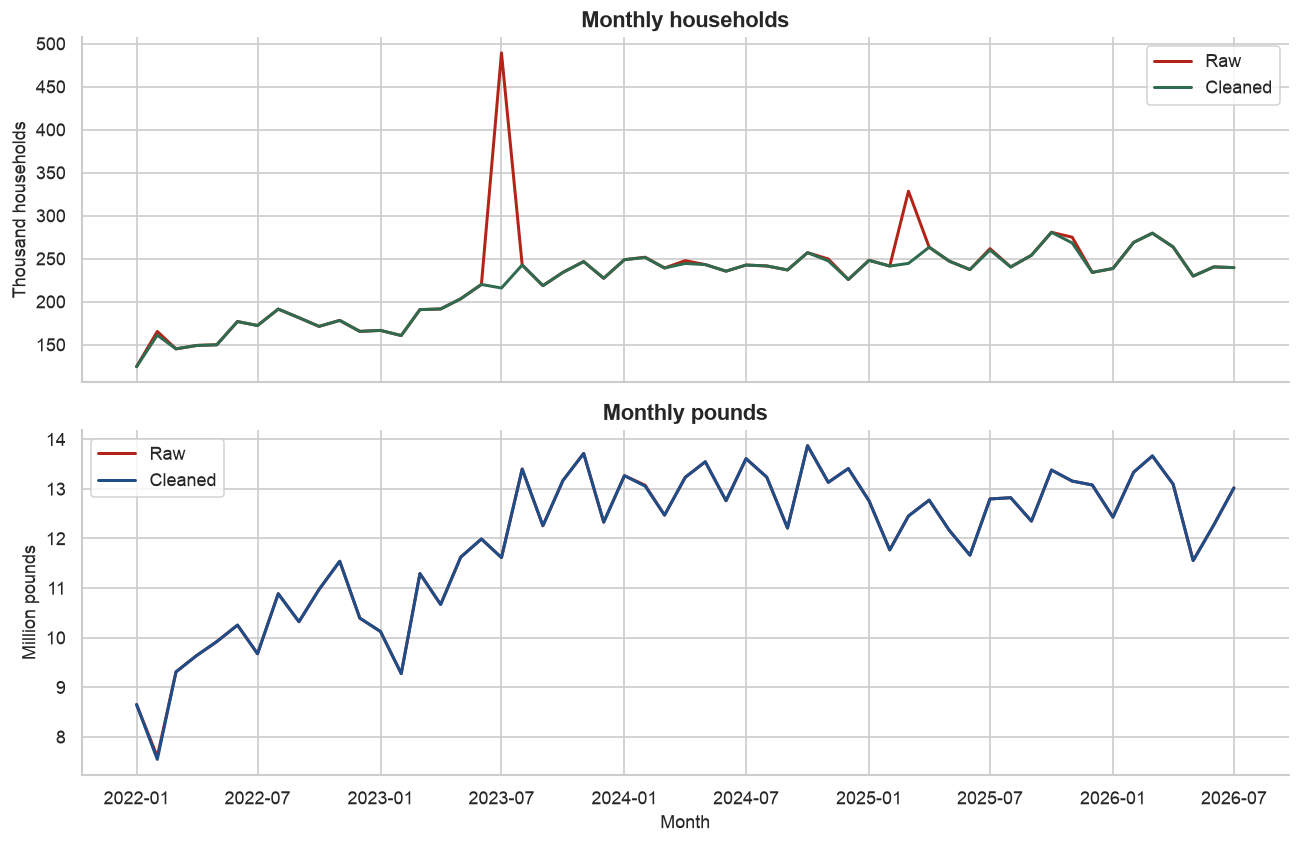

July 2023 households 489,210 → 215,825
March 2025 households 328,368 → 244,459


In [23]:
raw_hh = fs.groupby("DateForSearch")["HouseholdsReg"].sum().sort_index()
cln_hh = f2.groupby("DateForSearch")["HouseholdsReg"].sum().sort_index()
raw_lb = fs.groupby("DateForSearch")["PoundsReg"].sum().sort_index() / 1e6
cln_lb = f2.groupby("DateForSearch")["PoundsReg"].sum().sort_index() / 1e6
for series in (raw_hh, cln_hh, raw_lb, cln_lb):
    series.index = pd.to_datetime(series.index)

fig, axes = plt.subplots(2, 1, figsize=(11, 7.2), sharex=True)
axes[0].plot(raw_hh.index, raw_hh.values / 1e3, color=PALETTE["red"], lw=1.8, label="Raw")
axes[0].plot(cln_hh.index, cln_hh.values / 1e3, color=PALETTE["green"], lw=1.8, label="Cleaned")
axes[0].set_ylabel("Thousand households")
axes[0].set_title("Monthly households")
axes[0].legend()
axes[1].plot(raw_lb.index, raw_lb.values, color=PALETTE["red"], lw=1.8, label="Raw")
axes[1].plot(cln_lb.index, cln_lb.values, color=PALETTE["blue"], lw=1.8, label="Cleaned")
axes[1].set_ylabel("Million pounds")
axes[1].set_xlabel("Month")
axes[1].set_title("Monthly pounds")
axes[1].legend()
fig.tight_layout()
plt.show()

print("July 2023 households", f"{int(raw_hh.loc['2023-07-01']):,}", "→", f"{int(cln_hh.loc['2023-07-01']):,}")
print("March 2025 households", f"{int(raw_hh.loc['2025-03-01']):,}", "→", f"{int(cln_hh.loc['2025-03-01']):,}")


**Households move. Pounds and person-visits do not.** July 2023 drops by the Waseca typo (273,385 households against 646 people). March 2025 drops by the Ramsey-Suburbs row. From 2022 to 2025, pounds still rise about 27% and person-visits about 61%, so pounds per person still fall.


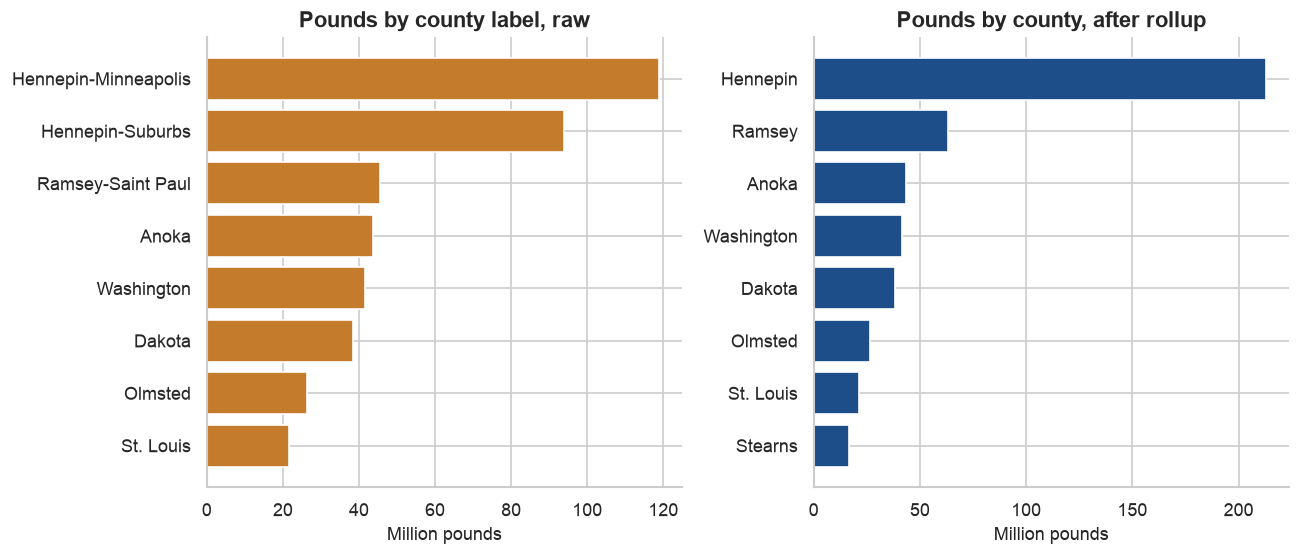

Food-bank names. The starred and “Inc.” labels are folded into the plain name.


,million_lb_raw,million_lb_clean
FoodBank,,
Channel One Regional Food Bank,26.66,66.77
Channel One Regional Food Bank*,40.11,NaN
North Country Food Bank,31.46,32.12
North Country Food Bank Inc.,0.65,NaN



Helpline geography, same contacts (duplicate IDs removed, from January 2023)


,measure,raw,cleaned
0,Distinct county labels,118.000,88.000
1,Share on a Minnesota county,0.567,0.659
2,Share still missing,0.327,0.327


How call counties were resolved


,contacts
county_how,
direct,28172
missing,16235
metro_split,4002
out_of_state,710
alias,565
unresolved,1



Redemption. Sum first, then divide. Missing redeemed values stay missing.


,program,window,redeemed_over_distributed,share_above_100pct,n
0,SNAP,Market day,0.986,0.275,9434
1,SNAP,Site × month,1.004,0.316,2380
2,SNAP,"Site, full history",0.999,0.125,128
3,Market Bucks,Market day,1.172,0.336,8784
4,Market Bucks,Site × month,1.171,0.346,2342
5,Market Bucks,"Site, full history",1.167,0.242,128


In [24]:
raw_cty = fs.groupby(fs["County"].fillna("(missing)"))["PoundsReg"].sum().sort_values(ascending=False).head(8) / 1e6
cln_cty = f2.groupby(f2["County"].fillna("(missing)"))["PoundsReg"].sum().sort_values(ascending=False).head(8) / 1e6

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].barh(raw_cty.index[::-1].astype(str), raw_cty.values[::-1], color=PALETTE["gold"])
axes[0].set_title("Pounds by county label, raw")
axes[0].set_xlabel("Million pounds")
axes[1].barh(cln_cty.index[::-1].astype(str), cln_cty.values[::-1], color=PALETTE["blue"])
axes[1].set_title("Pounds by county, after rollup")
axes[1].set_xlabel("Million pounds")
fig.tight_layout()
plt.show()

split_names = [
    "Channel One Regional Food Bank",
    "Channel One Regional Food Bank*",
    "North Country Food Bank",
    "North Country Food Bank Inc.",
]
banks = pd.DataFrame({
    "million_lb_raw": fs.groupby("FoodBank")["PoundsReg"].sum().reindex(split_names) / 1e6,
    "million_lb_clean": f2.groupby("FoodBank")["PoundsReg"].sum().reindex(split_names) / 1e6,
}).round(2)
print("Food-bank names. The starred and “Inc.” labels are folded into the plain name.")
display(banks)

mn = set(MN_COUNTIES)
geo = pd.DataFrame([
    {
        "measure": "Distinct county labels",
        "raw": int(calls_base["County"].nunique(dropna=True)),
        "cleaned": int(c2["County"].nunique(dropna=True)),
    },
    {
        "measure": "Share on a Minnesota county",
        "raw": round(calls_base["County"].isin(mn).mean(), 3),
        "cleaned": round(c2["County"].isin(mn).mean(), 3),
    },
    {
        "measure": "Share still missing",
        "raw": round(calls_base["County"].isna().mean() + calls_base["County"].isin(["(Unknown)"]).mean(), 3),
        "cleaned": round(c2["County"].isna().mean(), 3),
    },
])
print("\nHelpline geography, same contacts (duplicate IDs removed, from January 2023)")
display(geo)
print("How call counties were resolved")
display(c2["county_how"].value_counts().to_frame("contacts"))

def rate_row(program, window, distributed, redeemed):
    both = distributed.notna() & redeemed.notna() & distributed.gt(0)
    return {
        "program": program,
        "window": window,
        "redeemed_over_distributed": round(float(redeemed.loc[both].sum() / distributed.loc[both].sum()), 3),
        "share_above_100pct": round(float((redeemed.loc[both] > distributed.loc[both] + 0.01).mean()), 3),
        "n": int(both.sum()),
    }

life = m2.groupby("_id_site")[["SNAPDistributed", "SNAPRedeemed", "MBDistributed", "MBRedeemed"]].sum(min_count=1)
rates = pd.DataFrame([
    rate_row("SNAP", "Market day", mb["SNAPDistributed"], mb["SNAPRedeemed"]),
    rate_row("SNAP", "Site × month", mm["SNAPDistributed"], mm["SNAPRedeemed"]),
    rate_row("SNAP", "Site, full history", life["SNAPDistributed"], life["SNAPRedeemed"]),
    rate_row("Market Bucks", "Market day", mb["MBDistributed"], mb["MBRedeemed"]),
    rate_row("Market Bucks", "Site × month", mm["MBDistributed"], mm["MBRedeemed"]),
    rate_row("Market Bucks", "Site, full history", life["MBDistributed"], life["MBRedeemed"]),
])
print("\nRedemption. Sum first, then divide. Missing redeemed values stay missing.")
display(rates)


**Geography and rates**

- Hennepin is one county after the rollup (Minneapolis plus suburbs), about 213 million pounds. Ramsey similarly combines Saint Paul and the suburbs.
- Helpline typos and metro splits now join to those counties. The share of contacts on a Minnesota county goes from 57% to 66%. About a third of contacts still have no county; those stay missing. One label, `Cottonwood/Brown`, cannot be assigned to a single county.
- SNAP redeemed ÷ distributed settles at **99.9%** over each site's full history. A market-day or site-month rate still splits issuance from a later redemption. Market Bucks stays near **117%** even over a site's full history, so that ratio is not a usable redemption rate.


## 11. Analysis on the cleaned extracts

Sections 2–6 profile the raw files, including the household typos. This section repeats the analysis on `cleaned/`. Person counts are still monthly headcounts, so a sum across months counts repeat visits again. 2026 runs through July.


In [25]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PALETTE = {
    "ink": "#1F2933",
    "green": "#2F6B4F",
    "gold": "#C47B2B",
    "blue": "#1D4E89",
    "red": "#B42318",
}

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 4.6),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "semibold",
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "figure.dpi": 120,
})

fs = pd.read_csv(Path("cleaned") / "org_FSStats.csv", parse_dates=["DateForSearch"])
orgs = pd.read_csv(Path("cleaned") / "Organization.csv")
calls = pd.read_csv(Path("cleaned") / "IncomingCall.csv", parse_dates=["Date"])
mb = pd.read_csv(Path("cleaned") / "marketbucksUsage.csv", parse_dates=["Dated"])
fs["_id_site"] = fs["_id_site"].astype(float)
orgs["__ID"] = orgs["__ID"].astype(float)
mb["_id_site"] = mb["_id_site"].astype(float)

org_attrs = orgs[["__ID", "SuperRegion", "Region", "TefapStatus", "SuperShelfStatus", "City", "AgencyType"]].drop_duplicates("__ID")
shelf = fs.merge(org_attrs, left_on="_id_site", right_on="__ID", how="left", suffixes=("", "_org"))

print(f"Food shelves {len(fs):,} site-months, {fs['_id_site'].nunique()} sites")
print(f"Organizations {len(orgs):,}  |  Market days {len(mb):,}  |  Helpline {len(calls):,}")


Food shelves 28,243 site-months, 665 sites
Organizations 1,202  |  Market days 13,294  |  Helpline 49,685


Active 1073 | inactive 121
12-month pound average filled: 586
TEFAP eligible flag: 717 | on Find Help map: 646
Certified SuperShelf: 63


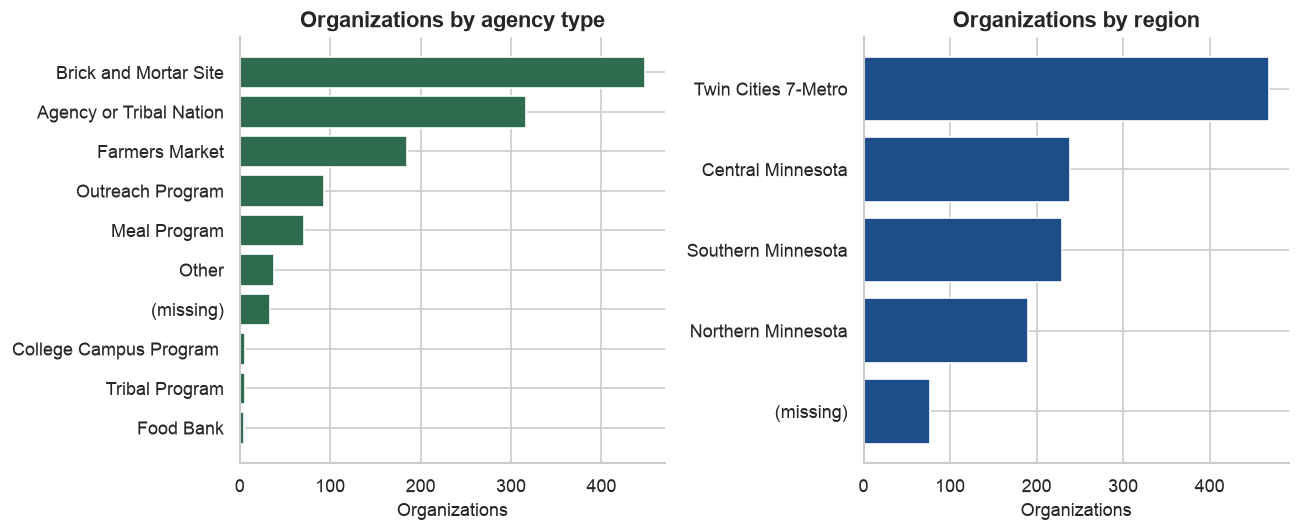

In [26]:
print("Active", int((orgs["ActiveInactive"] == "Active").sum()),
      "| inactive", int((orgs["ActiveInactive"] == "Inactive").sum()))
print("12-month pound average filled:", int(orgs["z12MoAverage_Pounds"].notna().sum()))
print("TEFAP eligible flag:", int((orgs["isTEFAPEligible"] == 1).sum()),
      "| on Find Help map:", int((orgs["isFindHelpMap"] == 1).sum()))
print("Certified SuperShelf:", int((orgs["SuperShelfStatus"] == "Certified").sum()))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
atype = orgs["AgencyType"].fillna("(missing)").value_counts()
axes[0].barh(atype.index[::-1], atype.values[::-1], color=PALETTE["green"])
axes[0].set_title("Organizations by agency type")
axes[0].set_xlabel("Organizations")
region = orgs["Region"].fillna("(missing)").value_counts()
axes[1].barh(region.index[::-1], region.values[::-1], color=PALETTE["blue"])
axes[1].set_title("Organizations by region")
axes[1].set_xlabel("Organizations")
fig.tight_layout()
plt.show()


,sites,pounds_m,households_m,individuals_m,lb_per_person,lb_per_household
_Year,,,,,,
2022,560,118.67,1.96,5.65,21.02,60.6
2023,569,141.88,2.52,7.76,18.29,56.2
2024,575,157.80,2.91,9.15,17.25,54.2
2025,530,151.16,3.02,9.09,16.63,50.1
2026,532,89.37,1.76,5.44,16.43,50.8


2022 → 2025: pounds +27%, person-visits +61%, households +54%
Sites reporting: 560 → 530
2026 through July is 89.4M pounds; twelve-month pace would be 153M


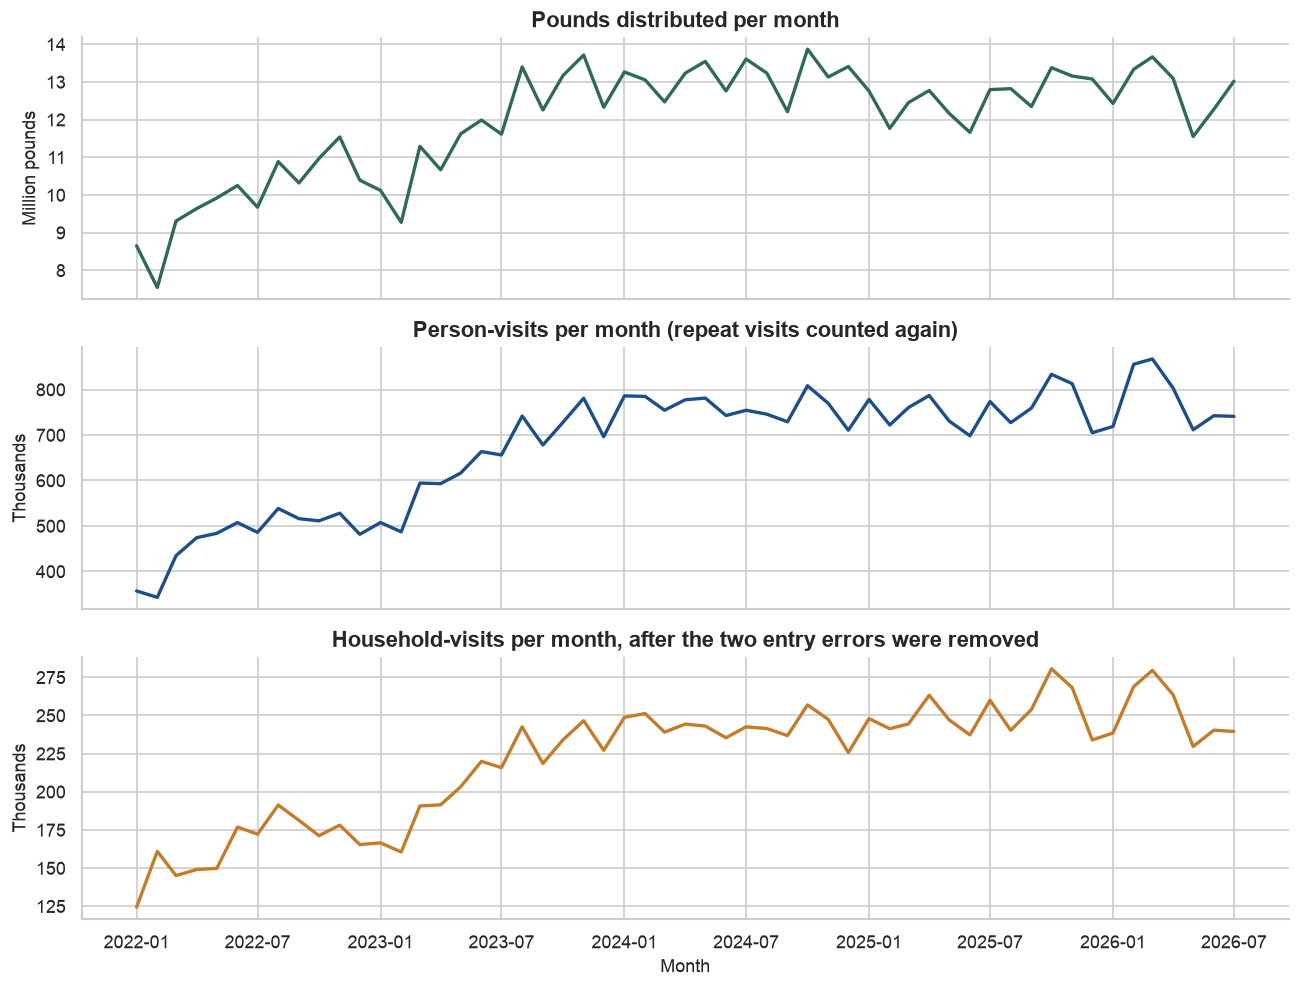

In [27]:
yearly = (
    fs.groupby("_Year")
    .agg(
        sites=("_id_site", "nunique"),
        pounds=("PoundsReg", "sum"),
        households=("HouseholdsReg", "sum"),
        individuals=("IndividualsReg", "sum"),
    )
    .astype({"sites": int})
)
yearly["lb_per_person"] = yearly["pounds"] / yearly["individuals"]
yearly["lb_per_household"] = yearly["pounds"] / yearly["households"]
show = yearly.copy()
show["pounds_m"] = (show["pounds"] / 1e6).round(2)
show["households_m"] = (show["households"] / 1e6).round(2)
show["individuals_m"] = (show["individuals"] / 1e6).round(2)
show["lb_per_person"] = show["lb_per_person"].round(2)
show["lb_per_household"] = show["lb_per_household"].round(1)
display(show[["sites", "pounds_m", "households_m", "individuals_m", "lb_per_person", "lb_per_household"]])

p22, p25 = yearly.loc[2022, "pounds"], yearly.loc[2025, "pounds"]
i22, i25 = yearly.loc[2022, "individuals"], yearly.loc[2025, "individuals"]
h22, h25 = yearly.loc[2022, "households"], yearly.loc[2025, "households"]
print(f"2022 → 2025: pounds {p25 / p22 - 1:+.0%}, person-visits {i25 / i22 - 1:+.0%}, households {h25 / h22 - 1:+.0%}")
print(f"Sites reporting: {int(yearly.loc[2022, 'sites'])} → {int(yearly.loc[2025, 'sites'])}")
print(f"2026 through July is {yearly.loc[2026, 'pounds'] / 1e6:.1f}M pounds; twelve-month pace would be {yearly.loc[2026, 'pounds'] / 7 * 12 / 1e6:.0f}M")

monthly = (
    fs.groupby("DateForSearch")
    .agg(pounds=("PoundsReg", "sum"), individuals=("IndividualsReg", "sum"), households=("HouseholdsReg", "sum"))
    .sort_index()
)
fig, axes = plt.subplots(3, 1, figsize=(11, 8.4), sharex=True)
axes[0].plot(monthly.index, monthly["pounds"] / 1e6, color=PALETTE["green"], lw=2)
axes[0].set_ylabel("Million pounds")
axes[0].set_title("Pounds distributed per month")
axes[1].plot(monthly.index, monthly["individuals"] / 1e3, color=PALETTE["blue"], lw=2)
axes[1].set_ylabel("Thousands")
axes[1].set_title("Person-visits per month (repeat visits counted again)")
axes[2].plot(monthly.index, monthly["households"] / 1e3, color=PALETTE["gold"], lw=2)
axes[2].set_ylabel("Thousands")
axes[2].set_xlabel("Month")
axes[2].set_title("Household-visits per month, after the two entry errors were removed")
fig.tight_layout()
plt.show()


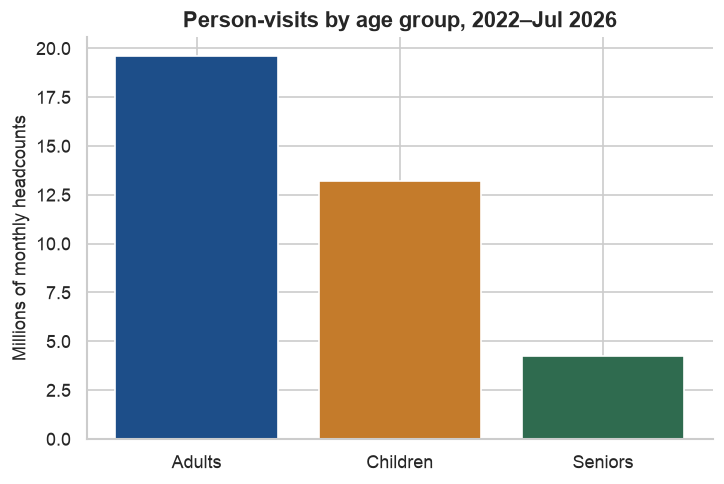

             share
AdultsReg    0.528
ChildrenReg  0.357
SeniorsReg   0.115


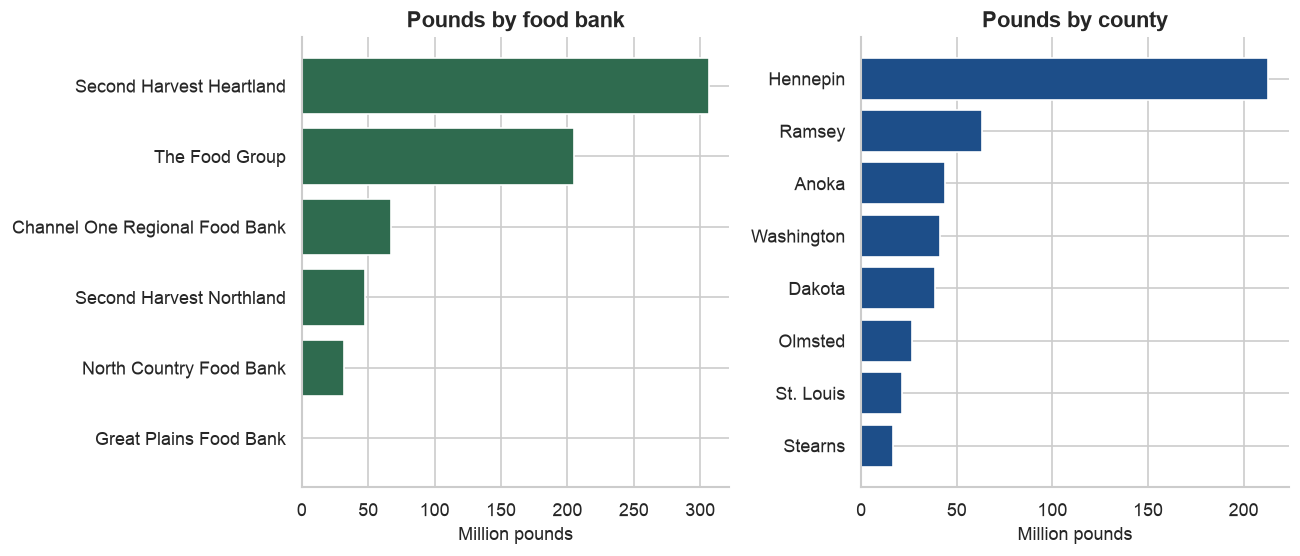

In [28]:
age = fs[["AdultsReg", "ChildrenReg", "SeniorsReg"]].sum()
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.bar(["Adults", "Children", "Seniors"], age.values / 1e6, color=[PALETTE["blue"], PALETTE["gold"], PALETTE["green"]])
ax.set_ylabel("Millions of monthly headcounts")
ax.set_title("Person-visits by age group, 2022–Jul 2026")
fig.tight_layout()
plt.show()
print((age / age.sum()).round(3).to_frame("share"))

banks = fs.groupby(fs["FoodBank"].fillna("(missing)"))["PoundsReg"].sum().sort_values(ascending=False).head(6) / 1e6
counties = fs.groupby(fs["County"].fillna("(missing)"))["PoundsReg"].sum().sort_values(ascending=False).head(8) / 1e6
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
axes[0].barh(banks.index[::-1], banks.values[::-1], color=PALETTE["green"])
axes[0].set_xlabel("Million pounds")
axes[0].set_title("Pounds by food bank")
axes[1].barh(counties.index[::-1].astype(str), counties.values[::-1], color=PALETTE["blue"])
axes[1].set_xlabel("Million pounds")
axes[1].set_title("Pounds by county")
fig.tight_layout()
plt.show()


Pounds per person-visit, 2022 vs 2025

Region


_Year,2022,2025,change,pounds_2025_m,sites_2025
Region,,,,,
Central Minnesota,27.64,21.80,-5.84,18.75,110
Southern Minnesota,21.33,16.92,-4.41,25.92,106
Twin Cities 7-Metro,19.48,15.33,-4.14,95.93,212
Northern Minnesota,25.00,24.34,-0.66,6.16,89



SuperRegion


_Year,2022,2025,change,pounds_2025_m,sites_2025
SuperRegion,,,,,
Non-Metro,23.92,19.22,-4.70,50.82,305
Metro,19.48,15.33,-4.14,95.93,212



TEFAP


_Year,2022,2025,change,pounds_2025_m,sites_2025
tefap,,,,,
Not TEFAP active,18.36,13.41,-4.95,3.72,33
TEFAP active,21.31,16.73,-4.58,147.44,497



SuperShelf


_Year,2022,2025,change,pounds_2025_m,sites_2025
supershelf,,,,,
Certified SuperShelf,25.97,20.03,-5.94,36.49,63
Not certified,19.93,15.78,-4.15,114.67,467



Sites in both 2022 and 2025: 492 (left after 2022: 68, new in 2025: 38)


,pounds_m,individuals_m,lb_per_person
_Year,,,
2022,110.00,5.15,21.38
2025,144.29,8.73,16.54


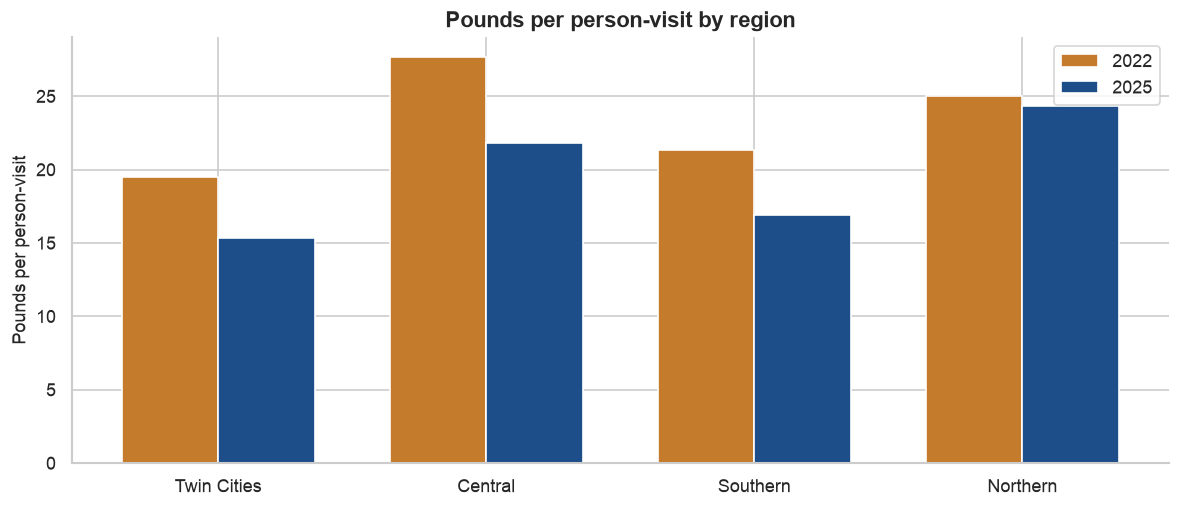

In [29]:
def ppp_table(frame, col):
    g = (
        frame.loc[frame["_Year"].isin([2022, 2025])]
        .groupby(["_Year", col])
        .agg(pounds=("PoundsReg", "sum"), individuals=("IndividualsReg", "sum"), sites=("_id_site", "nunique"))
    )
    g["lb_per_person"] = g["pounds"] / g["individuals"]
    wide = g["lb_per_person"].unstack("_Year")
    wide["change"] = wide[2025] - wide[2022]
    wide["pounds_2025_m"] = g["pounds"].unstack("_Year")[2025] / 1e6
    wide["sites_2025"] = g["sites"].unstack("_Year")[2025]
    return wide.sort_values("change")

shelf["tefap"] = np.where(shelf["TefapStatus"].eq("Active"), "TEFAP active", "Not TEFAP active")
shelf["supershelf"] = np.where(shelf["SuperShelfStatus"].eq("Certified"), "Certified SuperShelf", "Not certified")

print("Pounds per person-visit, 2022 vs 2025")
for label, col in [("Region", "Region"), ("SuperRegion", "SuperRegion"), ("TEFAP", "tefap"), ("SuperShelf", "supershelf")]:
    print(f"\n{label}")
    display(ppp_table(shelf, col).round(2))

sites_2022 = set(fs.loc[fs["_Year"] == 2022, "_id_site"])
sites_2025 = set(fs.loc[fs["_Year"] == 2025, "_id_site"])
both = sites_2022 & sites_2025
panel = fs[fs["_id_site"].isin(both) & fs["_Year"].isin([2022, 2025])]
panel_y = panel.groupby("_Year").agg(pounds=("PoundsReg", "sum"), individuals=("IndividualsReg", "sum"), households=("HouseholdsReg", "sum"))
panel_y["lb_per_person"] = panel_y["pounds"] / panel_y["individuals"]
print(f"\nSites in both 2022 and 2025: {len(both)} (left after 2022: {len(sites_2022 - sites_2025)}, new in 2025: {len(sites_2025 - sites_2022)})")
display(panel_y.assign(pounds_m=lambda d: (d["pounds"] / 1e6).round(2), individuals_m=lambda d: (d["individuals"] / 1e6).round(2)).round(2)[["pounds_m", "individuals_m", "lb_per_person"]])

region_order = ["Twin Cities 7-Metro", "Central Minnesota", "Southern Minnesota", "Northern Minnesota"]
reg = ppp_table(shelf.dropna(subset=["Region"]), "Region").reindex(region_order)
x = np.arange(len(reg))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - 0.18, reg[2022], width=0.36, color=PALETTE["gold"], label="2022")
ax.bar(x + 0.18, reg[2025], width=0.36, color=PALETTE["blue"], label="2025")
ax.set_xticks(x)
ax.set_xticklabels(["Twin Cities", "Central", "Southern", "Northern"])
ax.set_ylabel("Pounds per person-visit")
ax.set_title("Pounds per person-visit by region")
ax.legend()
fig.tight_layout()
plt.show()


**Pounds per person fell almost everywhere people are served.** From 2022 to 2025, pounds rose 27% and person-visits rose 61%, so pounds per person-visit fell from **21.0 to 16.6**. Reporting sites fell from 560 to 530, so the extra visits are not new sites. On the 492 sites present in both years the gap is wider: pounds **+31%**, person-visits **+70%**, pounds per person **21.4 to 16.5**.

The drop is about 4 to 6 pounds per person in the Twin Cities, Central, and Southern Minnesota. Northern Minnesota is nearly flat (25.0 to 24.3) because both pounds and visits stayed put. TEFAP-active sites are almost all of the 2025 volume (147 million of 151 million pounds) and fell from 21.3 to 16.7. Certified SuperShelves still hand out more pounds per person than other sites (20.0 vs 15.8 in 2025), down from 26.0 in 2022.

Hennepin, now one county, is 213 million pounds and fell from 23.8 to 16.8 pounds per person. Ramsey stayed near 16.5. Dakota rose from 17.6 to 20.8 as its pounds nearly doubled. Scott's drop (45 to 19) is site `1261` leaving the file after 2023, not a cut at the shelves that kept reporting.


,SNAP $000,MB $000,PB $000
year,,,
2022,615.0,320.0,310.0
2023,751.0,335.0,339.0
2024,643.0,402.0,408.0
2025,598.0,405.0,383.0
2026,238.0,142.0,0.0


Window totals: SNAP $2.84M, Market Bucks $1.60M, Produce Bucks $1.44M
Produce Bucks in 2026: $0


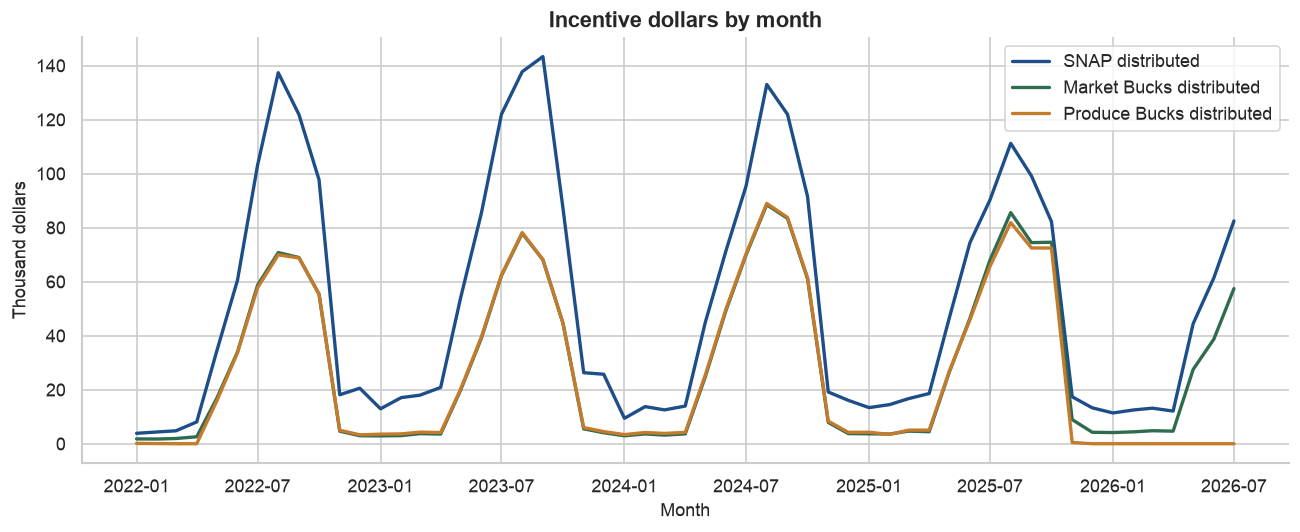

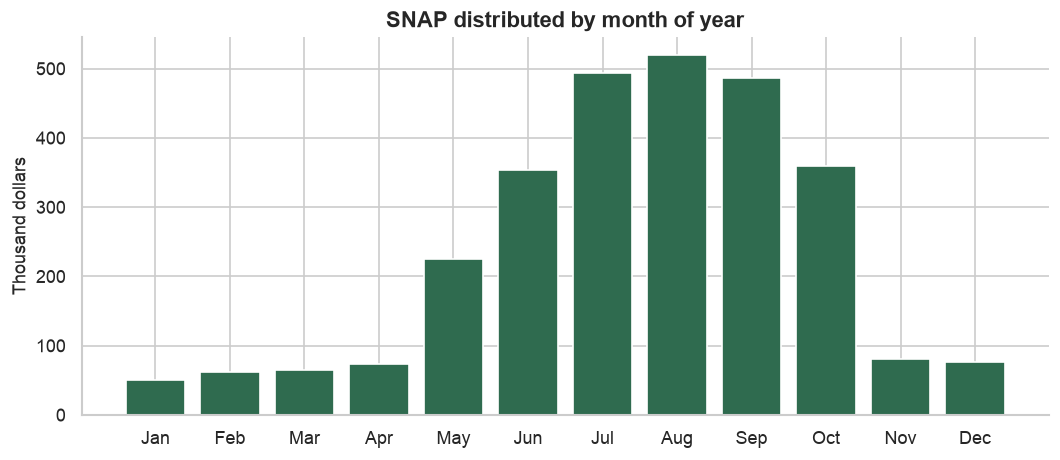

SNAP redeemed / distributed over each site's full history: 99.9%
Market Bucks, same window: 116.7%
SNAP dollars by region ($000)


,snap_000
Region,
Twin Cities 7-Metro,2113.0
Southern Minnesota,295.0
Northern Minnesota,260.0
Central Minnesota,129.0


In [30]:
mb = mb.copy()
mb["year"] = mb["Dated"].dt.year
mb["ym"] = mb["Dated"].dt.to_period("M").dt.to_timestamp()
yearly_mb = mb.groupby("year")[["SNAPDistributed", "MBDistributed", "PBDistributed"]].sum()
display((yearly_mb / 1e3).round(0).rename(columns=lambda c: c.replace("Distributed", " $000")))
print(f"Window totals: SNAP ${mb['SNAPDistributed'].sum()/1e6:.2f}M, Market Bucks ${mb['MBDistributed'].sum()/1e6:.2f}M, Produce Bucks ${mb['PBDistributed'].sum()/1e6:.2f}M")
print(f"Produce Bucks in 2026: ${mb.loc[mb['year']==2026, 'PBDistributed'].sum():,.0f}")

monthly_mb = mb.groupby("ym")[["SNAPDistributed", "MBDistributed", "PBDistributed"]].sum()
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.plot(monthly_mb.index, monthly_mb["SNAPDistributed"] / 1e3, color=PALETTE["blue"], lw=2, label="SNAP distributed")
ax.plot(monthly_mb.index, monthly_mb["MBDistributed"] / 1e3, color=PALETTE["green"], lw=2, label="Market Bucks distributed")
ax.plot(monthly_mb.index, monthly_mb["PBDistributed"] / 1e3, color=PALETTE["gold"], lw=2, label="Produce Bucks distributed")
ax.set_ylabel("Thousand dollars")
ax.set_xlabel("Month")
ax.set_title("Incentive dollars by month")
ax.legend()
fig.tight_layout()
plt.show()

season = mb.assign(month=mb["Dated"].dt.month).groupby("month")["SNAPDistributed"].sum()
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(season.index, season.values / 1e3, color=PALETTE["green"])
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.set_ylabel("Thousand dollars")
ax.set_title("SNAP distributed by month of year")
fig.tight_layout()
plt.show()

life = mb.groupby("_id_site")[["SNAPDistributed", "SNAPRedeemed", "MBDistributed", "MBRedeemed"]].sum(min_count=1)
def lifetime_rate(distributed, redeemed):
    both = distributed.notna() & redeemed.notna() & distributed.gt(0)
    return redeemed.loc[both].sum() / distributed.loc[both].sum()
print(f"SNAP redeemed / distributed over each site's full history: {lifetime_rate(life['SNAPDistributed'], life['SNAPRedeemed']):.1%}")
print(f"Market Bucks, same window: {lifetime_rate(life['MBDistributed'], life['MBRedeemed']):.1%}")
mbj = mb.merge(org_attrs[["__ID", "Region", "City"]], left_on="_id_site", right_on="__ID", how="left")
print("SNAP dollars by region ($000)")
display((mbj.groupby("Region")["SNAPDistributed"].sum().sort_values(ascending=False) / 1e3).round(0).to_frame("snap_000"))


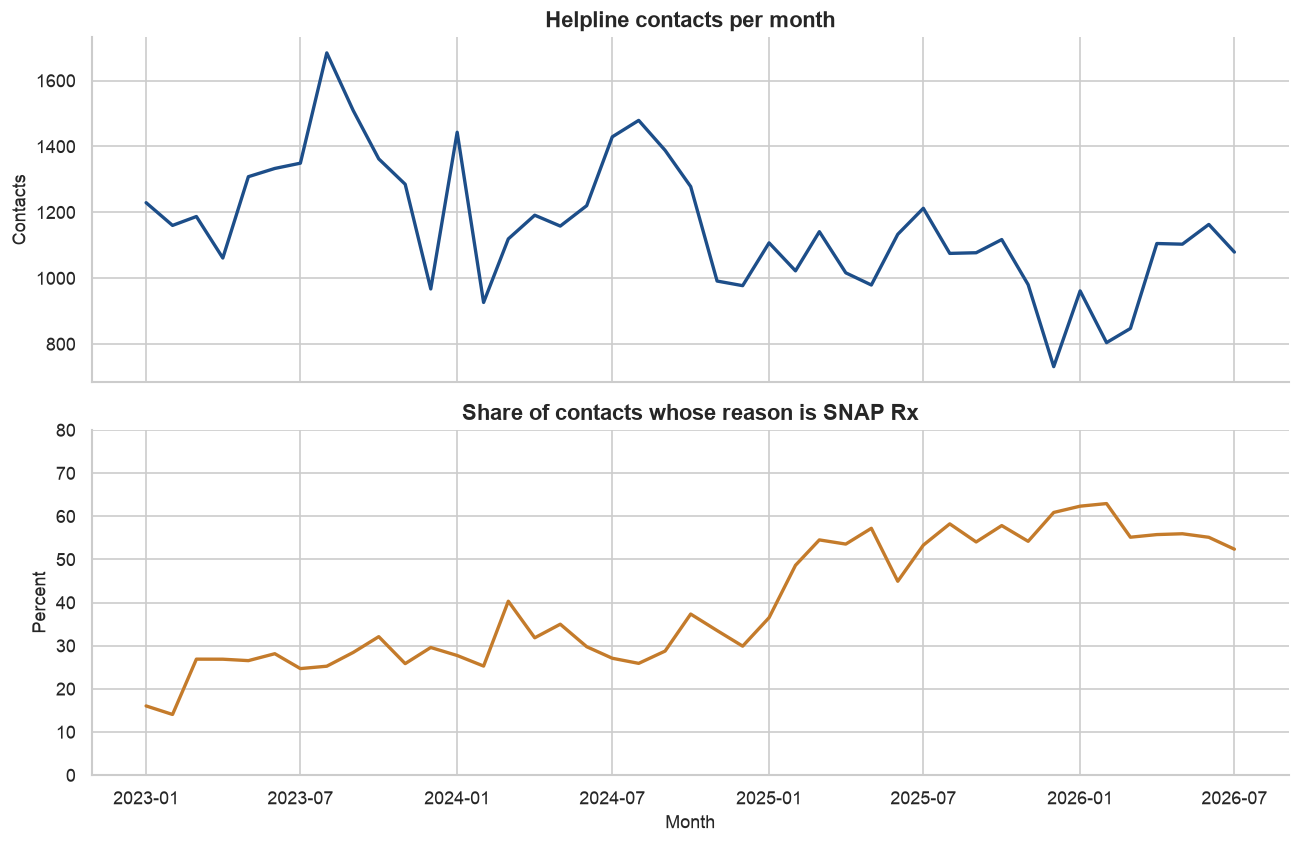

SNAP Rx share by year


,pct_snap_rx
year,
2023,25.5
2024,30.8
2025,52.5
2026,56.8


Food-shelf reason: 8108 | farmers-market reason: 262
No answer: 13492 | people on the ticket, mean: 1.22
Follow-up 1 complete: 16649 | follow-up 2: 874
County missing: 32.7%


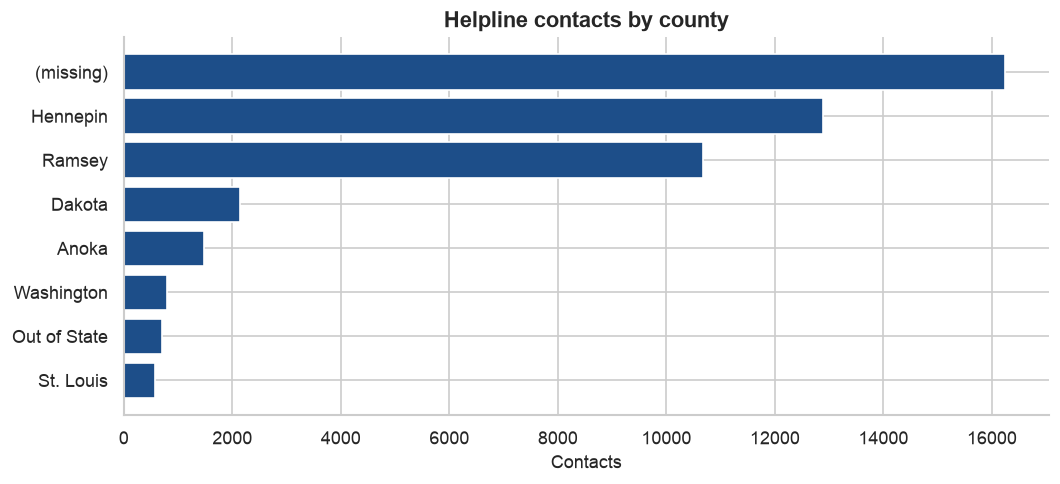

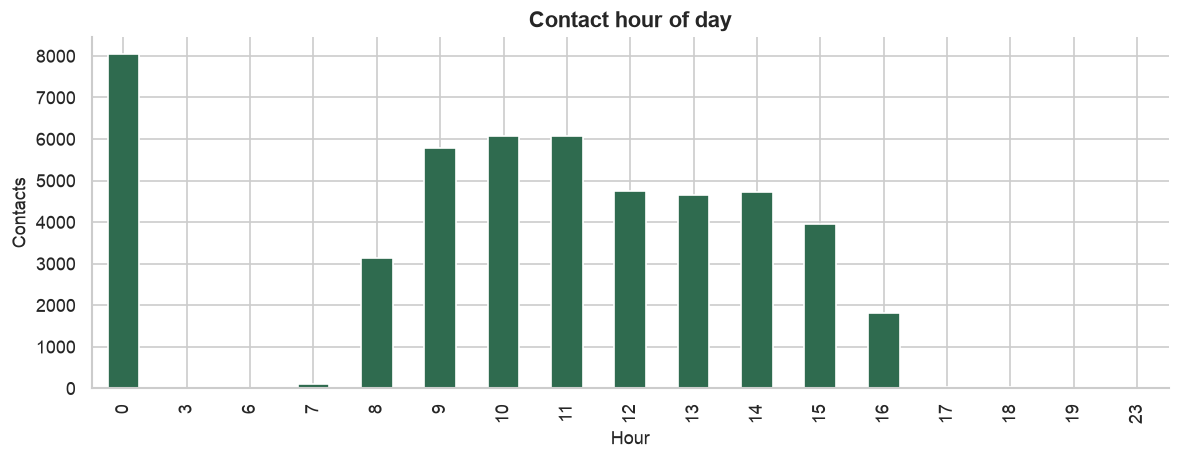

In [31]:
calls = calls.copy()
calls["year"] = calls["Date"].dt.year
calls["ym"] = calls["Date"].dt.to_period("M").dt.to_timestamp()
calls["is_rx"] = calls["PrimaryReasonForCall"].eq("SNAP Rx")

vol = calls.groupby("ym").size()
share = calls.groupby("ym")["is_rx"].mean()
fig, axes = plt.subplots(2, 1, figsize=(11, 7.2), sharex=True)
axes[0].plot(vol.index, vol.values, color=PALETTE["blue"], lw=2)
axes[0].set_ylabel("Contacts")
axes[0].set_title("Helpline contacts per month")
axes[1].plot(share.index, share.values * 100, color=PALETTE["gold"], lw=2)
axes[1].set_ylabel("Percent")
axes[1].set_xlabel("Month")
axes[1].set_title("Share of contacts whose reason is SNAP Rx")
axes[1].set_ylim(0, 80)
fig.tight_layout()
plt.show()

print("SNAP Rx share by year")
display(calls.groupby("year")["is_rx"].mean().mul(100).round(1).to_frame("pct_snap_rx"))
print("Food-shelf reason:", int((calls["PrimaryReasonForCall"] == "Food Shelf").sum()),
      "| farmers-market reason:", int(calls["PrimaryReasonForCall"].astype(str).str.contains("Market|Farm", case=False).sum()))
print("No answer:", int((calls["Call Answered"] == "No Answer").sum()),
      "| people on the ticket, mean:", round(calls["NumberInHouse"].mean(), 2))
print("Follow-up 1 complete:", int((calls["isFollowup1Complete"] == 1).sum()),
      "| follow-up 2:", int((calls["isFollowup2Complete"] == 1).sum()))
print(f"County missing: {calls['County'].isna().mean():.1%}")

top_counties = calls["County"].fillna("(missing)").value_counts().head(8)
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(top_counties.index[::-1].astype(str), top_counties.values[::-1], color=PALETTE["blue"])
ax.set_xlabel("Contacts")
ax.set_title("Helpline contacts by county")
fig.tight_layout()
plt.show()

hours = calls["CallTime"].dropna().astype(str).str.slice(0, 2)
hours = pd.to_numeric(hours, errors="coerce")
fig, ax = plt.subplots(figsize=(10, 4))
hours.value_counts().sort_index().plot(kind="bar", ax=ax, color=PALETTE["green"])
ax.set_xlabel("Hour")
ax.set_ylabel("Contacts")
ax.set_title("Contact hour of day")
fig.tight_layout()
plt.show()


In [32]:
lb = shelf.groupby("SuperRegion")["PoundsReg"].sum()
print("Share of pounds")
display((lb / lb.sum()).round(3).to_frame("share_of_pounds"))
known = calls["Region"].dropna()
known = known.loc[~known.astype(str).str.contains("Unknown")]
print(f"Share of helpline contacts in the Twin Cities, among those with a region: {(known == 'Twin Cities 7-Metro').mean():.1%}")
print(f"Share of all contacts in the Twin Cities, counting missing region in the base: {(calls['Region'] == 'Twin Cities 7-Metro').mean():.1%}")
print(f"Organizations in Non-Metro: {int((orgs['SuperRegion'] == 'Non-Metro').sum())} | Metro: {int((orgs['SuperRegion'] == 'Metro').sum())}")
matched = shelf["_id_site"].isin(set(orgs["__ID"]))
print(f"Food-shelf rows joined to an organization: {matched.mean():.1%}")
print(f"Joined rows whose organization has no super-region: {(matched & shelf['SuperRegion'].isna()).mean():.1%}")
print(f"Market Bucks sites: {mb['_id_site'].nunique()} of {(orgs['AgencyType'] == 'Farmers Market').sum()} farmers-market organizations")


Share of pounds


,share_of_pounds
SuperRegion,
Metro,0.651
Non-Metro,0.349


Share of helpline contacts in the Twin Cities, among those with a region: 87.5%
Share of all contacts in the Twin Cities, counting missing region in the base: 57.4%
Organizations in Non-Metro: 657 | Metro: 468
Food-shelf rows joined to an organization: 99.9%
Joined rows whose organization has no super-region: 2.9%
Market Bucks sites: 155 of 185 farmers-market organizations


**What the cleaned data says**

1. **Demand outgrew pounds, and it did so at the shelves that were already open.** All sites: pounds +27%, person-visits +61%, pounds per person 21.0 to 16.6. The same 492 sites: pounds +31%, person-visits +70%. Household-visits rose 54%, a bit slower than person-visits, so people per household-visit edged from 2.9 to 3.0. The July 2023 and March 2025 household spikes are gone.
2. **The decline is statewide except the north.** Twin Cities pounds per person fell from 19.5 to 15.3, Central from 27.6 to 21.8, Southern from 21.3 to 16.9. Northern stayed near 25. Metro and non-metro both lost about 4 to 5 pounds per person; non-metro still distributes more per person (19.2 vs 15.3 in 2025).
3. **The helpline is a clinical referral desk.** From January 2023, SNAP Rx is 25% of contacts, then 31%, 53%, and 57% in 2026 through July. Food-shelf navigation is still 8,108 contacts. About a third of contacts have no county.
4. **Market Bucks SNAP dollars peaked in 2023 ($751k) and have drifted down.** Market Bucks dollars held through 2025. Produce Bucks are $0 in 2026. Over a site's full history, SNAP redeemed is 99.9% of SNAP distributed. Market Bucks redeemed is about 117% of Market Bucks distributed, so that pair is not a redemption rate. Dollars are summer-heavy, with a winter floor.
5. **Volume sits in the Twin Cities; the roster does not.** Metro organizations are 468 of the partners with a region, against 657 non-metro, but metro sites distributed 65% of pounds. Among helpline contacts with a region, 87% are Twin Cities.
